# Unconfirmed TOIs at very small $a/R_\star$

The TESS candidate list screened for the hyperillumination study (TOI table of the NASA Exoplanet Archive / ExoFOP, 2026-10-20): unconfirmed rocky candidates (TFOPWG disposition PC, $R_p < 2\,R_\oplus$) with $a/R_\star < 3$. The TOI table has **no** $a/R_\star$, semi-major axis or stellar mass, so $a/R_\star$ is derived here from the period and the TIC stellar density, and the inclination from the catalogue transit duration. The four survivors of the screen -- TOI-7715.01, TOI-539.01, TOI-4644.01 and TOI-1242.01 -- are set up as `PlanetParams` and run through the standard analysis next to the two known record holders, TOI-2431 b and K2-141 b (`hi_planets_by_name`, archive / `CUSTOM` values), which are marked as comparison planets throughout (tinted axes).

1. **Literature parameters** -- one dict per candidate, every number with its source and uncertainty. Catalogue values only (TESS SPOC/QLP transit fit, TIC v8 host star); nothing is peer-reviewed.
2. **Derived quantities** -- $a/R_\star$ from Kepler III and $\rho_\star$, $R_p/R_\star$ from the depth, $b$ and $i$ from $T_{14}$, $a$ in AU, the Roche-limit check; validated on the TOI-table rows of TOI-2431 b and K2-141 b against their published values.
3. **PlanetParams** -- the objects, the geometry checks.
4. **Assumptions** shared by every planet (albedo, limb darkening, instruments) and the noise levels: PandExo only exists for the known planets, so the candidates carry **no error bars anywhere** (their fitted $A_B$ and $F$ do not depend on the noise).
5. **Comparison on MIRI/LRS** -- all six planets in one figure: the fitted $A_B$, the nightside flux, the geometry and the fit numbers in rows under the axes.
6. **Per planet** -- the copy-paste line for `HItargets_utils.CUSTOM`, `summary()`, the MIRI/LRS phase curve with its best point-source fits and residuals, the retrieved $A_B$ per JWST instrument, the nightside flux per instrument.
7. **Overview** -- the numbers of 5 and 6 in one table.

Runtime: the SPIDERMAN fits and PandExo take a few minutes per planet (process-parallel); sections 5 and 6 together are ~15-25 min.

In [1]:
import numpy as np
import pandas as pd
import os
import contextlib, io
import matplotlib.pyplot as plt
from dataclasses import replace
from astropy import constants as const
from joblib import Parallel, delayed
from joblib.externals.loky import get_reusable_executor  # to recycle leaky SPIDERMAN workers between planets
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman as sp
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from astro_utils import *
import batman_utils
from simple_bias_analysis import *
from simple_bias_analysis import _param_rows   # the rows of numbers under an axis, as in plot_false_F_bars / plot_planet_bias_bars (not exported by *)
from HItargets_utils import *
from plot_utils import paper_figure, paper_theme


def show_table(df, index="name"):
    '''A wide table transposed (quantities as rows, planets as columns) and formatted, so it renders in the notebook instead of wrapping.'''
    fmt = lambda v: "-" if v is None or (isinstance(v, float) and not np.isfinite(v)) else (f"{v:.4g}" if isinstance(v, (float, np.floating)) else v)
    t = df.set_index(index).T if index in df else df.T
    display(t.map(fmt) if hasattr(t, "map") else t.applymap(fmt))

## 1. Literature parameters

One dict per candidate. Every value is a **catalogue** number from the ExoFOP TOI table (`download_toi.php`, downloaded 2026-10-20; the NASA Exoplanet Archive TOI table carries the same values minus $M_\star$, the TFOP comments and the follow-up columns): period, $T_{14}$, depth and planet radius from the TESS SPOC or QLP transit fit of the alert, the host star from TIC v8 (Stassun et al. 2019). Uncertainties are the catalogue's, symmetric, `None` where it gives none. Two things to keep in mind:

- TIC $\log g$ and $M_\star$ are **not measured**: $M_\star$ comes from the TIC $T_{\rm eff}$-mass relation for dwarfs and $\log g$ from that mass and the Gaia-parallax radius, so $\log g$, $M_\star$ and $R_\star$ are one piece of information. $a/R_\star$ below rests on $M_\star$ and $R_\star$, and its error on the TIC's conservative mass error ($\pm 0.34$ dex in $\log g$ for TOI-539.01).
- The catalogue **planet radius** is the fitted $R_p/R_\star$ times whatever $R_\star$ the TIC had at alert time, and the TOI table's `pl_rade` can be stale (TOI-2431.01 is listed with $5.6\,R_\oplus$ while its own depth and $R_\star$ give $1.7$). $R_p/R_\star$ is therefore taken from the depth, with the catalogue radius kept for comparison only. The SPOC-fitted $R_p/R_\star$ with limb darkening sits in the DV report, not in the table.

`kmag_est`: the TOI table has no 2MASS $K$. It is estimated from the TESS magnitude and $T_{\rm eff}$ with a $T - K(T_{\rm eff})$ colour fit on 772 confirmed transiting-planet hosts (rms 0.11 mag, 2026-10-20) and is not used here; it is the normalisation magnitude a PandExo run for the candidate would need (replace it by the 2MASS $K_s$ from the ExoFOP target page, TIC ID below).

In [2]:
EXOFOP_DATE = "2026-10-20"   # download date of the ExoFOP TOI table every catalogue value below comes from

# TOI-7715.01 -- TIC 200001699. Alerted 2026-04-09 from a single sector (98, SPOC), the youngest and least followed-up candidate. ExoFOP: "potential multi; potential USP", TFOP master priority 1, 1 spectrum, no imaging, no ground photometry yet.
TOI_7715_01 = dict(
    name="TOI-7715.01", tic=200001699, disposition="PC",   # TFOPWG disposition
    period_d=0.323632,      period_d_err=0.000011,     # [d] SPOC transit fit (7.77 h)
    t14_h=0.946561,         t14_h_err=0.098669,        # [h] total transit duration, SPOC; +-10 %
    depth_ppm=488.04,       depth_ppm_err=39.96,       # [ppm] SPOC; +-8 %, i.e. +-4 % on Rp/R*
    r1_earth_cat=1.5427,    r1_earth_cat_err=0.5291,   # [R_earth] catalogue planet radius; +-34 %. Comparison only, r1 comes from the depth
    teff_K=4006.0,          teff_K_err=121.4,          # [K] TIC v8 (Gaia photometry)
    logg=4.58673,           logg_err=0.114836,         # [cgs] TIC v8, derived from M* and R* (see 1.)
    r2_rsun=0.668868,       r2_rsun_err=0.067176,      # [R_sun] TIC v8 (Gaia parallax + bolometric correction); +-10 %
    mstar_msun=0.63,        mstar_msun_err=0.077,      # [M_sun] TIC v8 Teff-mass relation; not used (log g carries it)
    met=None,                                          # [Fe/H] none in the catalogue
    dist_pc=57.00, tmag=10.640,                        # TIC v8
    kmag_est=8.61,          kmag_est_err=0.11,         # [mag] estimated from T mag and Teff (see 1.), NOT 2MASS; not used
)

# TOI-539.01 -- TIC 238004786. Alerted 2019-02-26 (sector 2), SPOC multisector fit over 13 sectors (1-65): best ephemeris of the set. ExoFOP: "a/Rs ~2; possibly evaporating", master priority 1, 9 ground light curves, 2 spectra, 3 imaging observations and still PC after 7 years.
TOI_539_01 = dict(
    name="TOI-539.01", tic=238004786, disposition="PC",
    period_d=0.309606,      period_d_err=0.000004,     # [d] SPOC multisector (7.43 h)
    t14_h=1.029893,         t14_h_err=0.164736,        # [h] +-16 %
    depth_ppm=257.71,       depth_ppm_err=14.78,       # [ppm] +-6 %
    r1_earth_cat=1.5527,    r1_earth_cat_err=0.3109,   # [R_earth] comparison only
    teff_K=4836.0,          teff_K_err=178.0,          # [K] TIC v8
    logg=4.44968,           logg_err=0.343852,         # [cgs] TIC v8; the largest log g error of the set -> +-26 % on a/R*
    r2_rsun=0.813125,       r2_rsun_err=0.053133,      # [R_sun] TIC v8; +-7 %
    mstar_msun=0.80,        mstar_msun_err=0.098,      # [M_sun] TIC v8; not used
    met=None,
    dist_pc=108.37, tmag=10.596,
    kmag_est=9.07,          kmag_est_err=0.11,
)

# TOI-4644.01 -- TIC 387423096. Alerted 2021-11-19 (QLP, sectors 42-44). ExoFOP: "small a/Rs; possibly variability; v-shaped" (the V shape is the false-positive risk: high b or a blend), master priority 2, 8 imaging observations, 2 spectra, no ground photometry.
TOI_4644_01 = dict(
    name="TOI-4644.01", tic=387423096, disposition="PC",
    period_d=0.318185,      period_d_err=0.000018,     # [d] QLP (7.64 h)
    t14_h=0.762,            t14_h_err=0.172,           # [h] +-23 %
    depth_ppm=480.0,        depth_ppm_err=2.58,        # [ppm] QLP; the quoted +-0.5 % is not credible at SNR 15 -- treat as a few %
    r1_earth_cat=1.7823,    r1_earth_cat_err=0.2293,   # [R_earth] comparison only
    teff_K=4242.23,         teff_K_err=142.3,          # [K] TIC v8
    logg=4.5065,            logg_err=0.119222,         # [cgs] TIC v8
    r2_rsun=0.75,           r2_rsun_err=0.08,          # [R_sun] TIC v8; +-11 %
    mstar_msun=0.66,        mstar_msun_err=0.080,      # [M_sun] TIC v8; not used
    met=-0.108,                                        # [Fe/H] TIC v8 (the only candidate with one), +-0.032
    dist_pc=88.78, tmag=11.051,
    kmag_est=9.17,          kmag_est_err=0.11,
)

# TOI-1242.01 -- TIC 198212955. Alerted 2019-10-17, SPOC over 17 sectors (northern CVZ, so also in JWST's). ExoFOP: "Possible L1 candidate; very short period", master priority 1, SNR 27, 10 ground light curves, 4 spectra, 6 imaging observations, still PC. Radius straddles the rocky cut (1.85 R_earth from the depth, 2.06 in the catalogue).
TOI_1242_01 = dict(
    name="TOI-1242.01", tic=198212955, disposition="PC",
    period_d=0.381485,      period_d_err=0.000001,     # [d] SPOC multisector (9.16 h)
    t14_h=0.565,            t14_h_err=0.154,           # [h] +-27 %; the shortest duration of the set -> b ~ 0.9
    depth_ppm=570.0,        depth_ppm_err=4.70,        # [ppm] SPOC; quoted +-0.8 %
    r1_earth_cat=2.0605,    r1_earth_cat_err=0.2555,   # [R_earth] comparison only; 11 % above the depth-based radius, i.e. fitted with an older, larger TIC R*
    teff_K=4255.0,          teff_K_err=128.2,          # [K] TIC v8
    logg=4.55641,           logg_err=0.106625,         # [cgs] TIC v8
    r2_rsun=0.71,           r2_rsun_err=0.07,          # [R_sun] TIC v8; +-10 %
    mstar_msun=0.665,       mstar_msun_err=0.083,      # [M_sun] TIC v8; not used
    met=None,
    dist_pc=110.02, tmag=11.598,
    kmag_est=9.73,          kmag_est_err=0.11,
)

CANDIDATES = [TOI_7715_01, TOI_539_01, TOI_4644_01, TOI_1242_01]

# The TOI-table rows of the two known planets, SAME columns and source, used only to validate the derivations of 2. against the published values (the analysis uses hi_planets_by_name for them).
TOI_2431_01 = dict(   # TOI-2431 b, TIC 258804746, CP. Published (Tas et al. 2026, archive): a/R* = 2.081, Rp/R* = 0.02131, i = 74.0 deg. The TOI row is poor: depth 540 +- 636 ppm, pl_rade 5.6 R_earth.
    name="TOI-2431.01 (TOI row)", tic=258804746, disposition="CP",
    period_d=0.224195, period_d_err=None, t14_h=0.292, t14_h_err=0.026, depth_ppm=540.0, depth_ppm_err=636.2, r1_earth_cat=5.5955, r1_earth_cat_err=1.955,
    teff_K=4079.0, teff_K_err=126.0, logg=4.58, logg_err=0.11, r2_rsun=0.68, r2_rsun_err=0.07, mstar_msun=0.64, mstar_msun_err=0.078, met=None, dist_pc=36.06, tmag=9.521, kmag_est=None, kmag_est_err=None,
)
TOI_6835_01 = dict(   # K2-141 b, TIC 301235044, KP. Published (Malavolta et al. 2018, Barragan et al. 2018; the CUSTOM entry): a/R* = 2.292, Rp/R* = 0.02037, i = 86.3 deg, T14 = 0.94 h.
    name="TOI-6835.01 (TOI row)", tic=301235044, disposition="KP",
    period_d=0.280325, period_d_err=None, t14_h=0.868, t14_h_err=0.134, depth_ppm=507.0, depth_ppm_err=32.0, r1_earth_cat=1.6483, r1_earth_cat_err=0.1457,
    teff_K=4477.0, teff_K_err=124.7, logg=4.56, logg_err=0.10, r2_rsun=0.72, r2_rsun_err=0.06, mstar_msun=0.70, mstar_msun_err=0.086, met=None, dist_pc=61.87, tmag=10.030, kmag_est=None, kmag_est_err=None,
)

## 2. Derived quantities

- **$a/R_\star$ from the stellar density.** Kepler III with $M_p \ll M_\star$ and $M_\star = \tfrac43\pi R_\star^3\rho_\star$ gives $(a/R_\star)^3 = G\rho_\star P^2/(3\pi)$ -- no stellar mass, no planet mass, no semi-major axis needed; $\rho_\star = 3g/(4\pi G R_\star)$ from the TIC $\log g$ and $R_\star$. This is the inverse of `astro_utils.kepler_period_days`. Its $1\sigma$ follows from $\mathrm{d}\ln(a/R_\star) = \tfrac13(\ln 10\,\mathrm{d}\log g - \mathrm{d}R_\star/R_\star)$. Calibrated on 365 TOIs that are confirmed planets (2026-10-20): derived / published $a/R_\star$ has median 0.98 and a 16-84 % range of 0.91-1.03.
- **$R_p/R_\star = \sqrt{\delta}$** from the depth, i.e. without limb darkening: up to ~10 % high for a central transit of a K dwarf in the TESS band, exact for a grazing one.
- **$b$ and $i$ from $T_{14}$.** Winn (2010) eq. 14 for a circular orbit, inverted exactly: with $s = \sin(\pi T_{14}/P)$, $b^2 = [(1+k)^2 - (a/R_\star)^2 s^2]/(1-s^2)$ and $i = \arccos(b\,R_\star/a)$. Loose, because the TOI durations are good to 10-30 %; where $T_{14}$ is longer than a central transit allows ($b^2<0$) the inclination falls back to $90°$. The phase-curve amplitude of a tidally locked map goes roughly as $\sin i$, so $70°$ against $90°$ is a ~5 % effect; only the occultation shape really depends on $b$.
- **$a$ in AU** only feeds the light-travel-time correction of `PlanetParams.a_AU`.
- **Roche check**: $a_{\rm R}/R_\star = c\,(\rho_\star/\rho_p)^{1/3}$ (`astro_utils.roche_limit_a_rs`, $c = 2.456$) at Earth bulk density; a candidate inside it is either iron-rich or not a planet.
- $e = 0$, $\omega = 90°$: the tidal circularisation time of a 7-9 h orbit is negligible, and `DEFAULT_W_DEG` is the transit convention of `HItargets_utils`.

In [3]:
R_SUN_CM, R_EARTH_CM, AU_CM = const.R_sun.cgs.value, const.R_earth.cgs.value, const.au.cgs.value
RHO_P_ROCHE = 5.5   # [g/cm^3] Earth bulk density for the Roche-limit check (HypotheticalExtremePlanet.ipynb uses 8.0 for Earth composition compressed to 1.5 R_earth)


def stellar_density(logg, r2_rsun):
    '''Mean stellar density [g/cm^3] from log g (cgs) and R* [R_sun]: rho = 3 g / (4 pi G R*). With the TIC's derived log g this is M* / (4/3 pi R*^3) in disguise.'''
    return 3. * 10. ** logg / (4. * np.pi * G_CGS * r2_rsun * R_SUN_CM)


def a_over_r2_from_density(period_d, rho_star):
    '''a/R* of a circular orbit from P [d] and rho* [g/cm^3]: (a/R*)^3 = G rho* P^2 / (3 pi) (Kepler III, M_p << M*). Inverse of astro_utils.kepler_period_days.'''
    return (G_CGS * rho_star * (period_d * 86400.) ** 2 / (3. * np.pi)) ** (1. / 3.)


def a_over_r2_err(a_over_r2, logg_err, r2_rsun, r2_rsun_err):
    '''1 sigma of a/R* from the catalogue errors: d ln(a/R*) = (ln10 dlogg - dR*/R*) / 3, in quadrature (TIC log g and R* taken as independent, which they are not quite -- an overestimate).'''
    return a_over_r2 * np.sqrt((np.log(10.) / 3. * logg_err) ** 2 + (r2_rsun_err / (3. * r2_rsun)) ** 2)


def r1_over_r2_from_depth(depth_ppm):
    '''Rp/R* = sqrt(depth), no limb darkening (see 2.).'''
    return np.sqrt(depth_ppm * 1e-6)


def a_AU_from(a_over_r2, r2_rsun):
    '''Semi-major axis [AU], for PlanetParams.a_AU only.'''
    return a_over_r2 * r2_rsun * R_SUN_CM / AU_CM


def t14_central_h(period_d, a_over_r2, r1_over_r2):
    '''The longest possible total duration [h], b = 0 (Winn 2010 eq. 14): the catalogue T14 must stay below it.'''
    return period_d / np.pi * np.arcsin((1. + r1_over_r2) / a_over_r2) * 24.


def impact_parameter_from_t14(period_d, t14_h, a_over_r2, r1_over_r2):
    '''b from the total duration of a circular transit, Winn 2010 eq. 14 inverted exactly: s = sin(pi T14 / P), b^2 = [(1 + k)^2 - (a/R*)^2 s^2] / (1 - s^2).
    NaN where T14 exceeds the central-transit duration (b^2 < 0: T14, a/R* or k is off) or b > 1 + k (no transit).'''
    s = np.sin(np.pi * t14_h / 24. / period_d)
    b2 = ((1. + r1_over_r2) ** 2 - (a_over_r2 * s) ** 2) / (1. - s ** 2)
    b = np.sqrt(b2) if b2 >= 0. else np.nan
    return b if b <= 1. + r1_over_r2 else np.nan


def inclination_from_b(b, a_over_r2, fallback=90.):
    '''i [deg] = arccos(b R*/a); the fallback (central transit) where b is NaN.'''
    return float(np.degrees(np.arccos(b / a_over_r2))) if np.isfinite(b) else fallback


def derived(p):
    '''Everything PlanetParams needs from one catalogue dict, plus the 1 sigma of a/R* and the geometry checks (b, central T14, Roche limit, depth-based radius in R_earth).'''
    rho = stellar_density(p["logg"], p["r2_rsun"])
    a_rs = a_over_r2_from_density(p["period_d"], rho)
    k = r1_over_r2_from_depth(p["depth_ppm"])
    b = impact_parameter_from_t14(p["period_d"], p["t14_h"], a_rs, k)
    return dict(rho_star=rho, a_over_r2=a_rs, a_over_r2_err=a_over_r2_err(a_rs, p["logg_err"], p["r2_rsun"], p["r2_rsun_err"]), r1_over_r2=k,
                r1_earth=k * p["r2_rsun"] * R_SUN_CM / R_EARTH_CM, a_AU=a_AU_from(a_rs, p["r2_rsun"]), b=b, incl=inclination_from_b(b, a_rs),
                t14_central_h=t14_central_h(p["period_d"], a_rs, k), a_roche=float(roche_limit_a_rs(rho / RHO_P_ROCHE)))


def planet_from_catalogue(p, incl=None):
    '''PlanetParams from a catalogue dict, in stellar radii (r2 = 1), circular; incl from the catalogue T14 unless given.'''
    d = derived(p)
    return PlanetParams(name=p["name"], period=p["period_d"], incl=d["incl"] if incl is None else incl, ecc=0.0, w=DEFAULT_W_DEG,
                        r1=d["r1_over_r2"], r2=1.0, R=d["a_over_r2"], T2_eff=p["teff_K"], a_AU=d["a_AU"], T14=p["t14_h"])


def custom_entry_line(pl, comment=""):
    '''The planet as one line of the CUSTOM dict in HItargets_utils.py (copy-paste).'''
    return (f'"{pl.name}": PlanetParams(name="{pl.name}", period={pl.period:.7f}, incl={pl.incl:.1f}, ecc={pl.ecc:.1f}, w={pl.w:.1f}, r1={pl.r1:.5f}, r2={pl.r2:.1f}, '
            f'R={pl.R:.3f}, T2_eff={pl.T2_eff:.1f}, a_AU={pl.a_AU:.5f}, T14={pl.T14:.3f}),' + (f"   # {comment}" if comment else ""))

### 2.1 Validation on the two known planets
The same derivations applied to the TOI-table rows of TOI-2431 b and K2-141 b, against the published values that `hi_planets_by_name` returns. What to look for: $a/R_\star$ within its $1\sigma$ of the published value but low by 4-5 % (the TIC density is the weak link, $\pm 9$ % here), $R_p/R_\star$ about 10 % high (no limb darkening), and the inclination from the catalogue $T_{14}$ well off the published one: the TOI durations of both planets are shorter than their published geometry implies (TOI-2431 b 0.29 h, the ExoFOP value that `HItargets_utils.OVERRIDES` replaces by 0.75 h; K2-141 b 0.87 h against the 0.98 h of $a/R_\star = 2.29$, $i = 86.3°$), so $b$ comes out too large and $i$ too small. The candidates' inclinations in 3. carry the same caveat.

In [4]:
comparison = hi_planets_by_name(["TOI-2431 b", "K2-141 b"])   # published geometry (archive row with OVERRIDES, CUSTOM entry)

rows = []
for p, pub in ((TOI_2431_01, comparison["TOI-2431 b"]), (TOI_6835_01, comparison["K2-141 b"])):
    d = derived(p)
    rows.append({"name": pub.name, "TOI row": p["name"], "a/R* derived": d["a_over_r2"], "a/R* +-": d["a_over_r2_err"], "a/R* published": pub.R / pub.r2, "derived / published": d["a_over_r2"] / (pub.R / pub.r2),
                 "Rp/R* derived": d["r1_over_r2"], "Rp/R* published": pub.r1 / pub.r2, "b derived": d["b"], "i derived [deg]": d["incl"], "i published [deg]": pub.incl,
                 "T14 catalogue [h]": p["t14_h"], "T14 central [h]": d["t14_central_h"], "T14 used [h]": pub.T14})
show_table(pd.DataFrame(rows))

name,TOI-2431 b,K2-141 b
TOI row,TOI-2431.01 (TOI row),TOI-6835.01 (TOI row)
a/R* derived,1.969,2.208
a/R* +-,0.1795,0.1803
a/R* published,2.081,2.292
derived / published,0.9464,0.9635
Rp/R* derived,0.02324,0.02252
Rp/R* published,0.02131,0.02037
b derived,0.9814,0.5832
i derived [deg],60.11,74.69
i published [deg],74,86.3


## 3. PlanetParams
The candidates from their dicts and the derivations of 2.; the comparison planets from `hi_planets_by_name` (their `CUSTOM` lines are printed in 6. for reference). The table gives the derived geometry of each candidate with its checks. What to look for: whether the catalogue $T_{14}$ lies below the central-transit duration (else the inclination fell back to $90°$), how far outside the Roche limit each planet sits ($a/a_{\rm R} > 1$), and how the depth-based radius compares with the catalogue one.

In [5]:
candidates = {p["name"]: planet_from_catalogue(p) for p in CANDIDATES}
planets = {**candidates, **comparison}                  # analysis order: the candidates, then the known planets
is_comparison = {nm: nm in comparison for nm in planets}

rows = []
for p in CANDIDATES:
    d, pl = derived(p), candidates[p["name"]]
    rows.append({"name": pl.name, "a/R*": d["a_over_r2"], "a/R* +-": d["a_over_r2_err"], "rho* [g/cm^3]": d["rho_star"], f"a_R/R* (rho_p = {RHO_P_ROCHE:g})": d["a_roche"], "a / a_R": d["a_over_r2"] / d["a_roche"],
                 "Rp/R* (depth)": d["r1_over_r2"], "Rp [R_earth] (depth)": d["r1_earth"], "Rp [R_earth] catalogue": p["r1_earth_cat"], "T14 catalogue [h]": p["t14_h"], "T14 central [h]": d["t14_central_h"],
                 "b": d["b"], "i [deg]": d["incl"], "a [AU]": d["a_AU"], "lit fraction [%]": 100 * pl.fraction_illuminated()})
show_table(pd.DataFrame(rows))

name,TOI-7715.01,TOI-539.01,TOI-4644.01,TOI-1242.01
a/R*,2.542,2.082,2.275,2.717
a/R* +-,0.2397,0.5513,0.2234,0.2396
rho* [g/cm^3],2.968,1.781,2.201,2.608
a_R/R* (rho_p = 5.5),2,1.686,1.81,1.915
a / a_R,1.271,1.234,1.257,1.419
Rp/R* (depth),0.02209,0.01605,0.02191,0.02387
Rp [R_earth] (depth),1.612,1.424,1.792,1.849
Rp [R_earth] catalogue,1.543,1.553,1.782,2.061
T14 catalogue [h],0.9466,1.03,0.762,0.565
T14 central [h],1.023,1.206,1.132,1.126


## 4. Assumptions shared by every planet
The same placeholders as `AB_Bias.ipynb` / `HypotheticalExtremePlanet.ipynb`: $A_B = 0.3$ for every planet (no albedo is known for any of them), band albedo $A = 0.1$ in the MIR, grey Eddington limb darkening, $u_B = 0.6$; MIRI/LRS for the phase-curve figures, 27 bins, 5 orbits; the per-instrument figures run over `retrieval_instruments` (the two NIRSpec/G395H arrays singly and jointly, MIRI/LRS, the three MIRI imaging bands) and the nightside bars over every band in `FILTER_LAMBDA_UM`.

**Noise levels.** The known planets get `HItargets_utils.rms_1min`: PandExo where it has a mode, `CUSTOM_SIGMA_1MIN` otherwise, and an instrument with neither (K2-141 b on MIRI imaging) drops out of their per-instrument figure. PandExo cannot be run for the candidates through `rms_1min` -- `pandexo_params` reads the archive aggregate, which does not have them -- so they get a placeholder noise level and **no error bars, mock data, Fisher $\sigma$, verdicts or $\chi^2$ anywhere**: the fitted $A_B$ and $F$ are noise-independent and are all that is shown for them. (Running PandExo for a candidate needs its 2MASS $K$ and an archive-independent entry point in `HItargets_utils`.)

In [6]:
u = [0.15, 0.08]                 # Band-integrated (MIR) quadratic stellar limb darkening coefficients [u1, u2] (placeholders from grey Eddington atmosphere)
u_B = 0.6                        # Bolometric linear stellar limb darkening coefficient (placeholder, from Sadh_Gavassino_2026)
A_B_true = 0.3                   # the assumed Bond albedo of every planet (as for TOI-2431 b in AB_Bias.ipynb); the fits inject and recover this value
A_model = ConstantBandAlbedo(.1) # band-integrated albedo of a rocky surface fixed to A = 0.1 in the MIR (small reflected part)
A = A_model(A_B_true)

instrument = "MIRI/LRS"          # the phase-curve figures
filter_path = filter_loc(instrument)
l1, l2 = filter_lambda(instrument)
n_bins = 27                      # bins per orbit
n_orbits = 5                     # orbits observed; enters only the Fisher sigmas and chi^2 of the known planets

with contextlib.redirect_stdout(io.StringIO()):   # mute "no stellar models provided, using blackbody approximation"
    stellar_grid = sp.stellar_grid.gen_grid(l1, l2, logg=4.5, response=filter_path)
# planet and sigma_1min are replaced per planet in 5. and 6.
cfg = FittingConfig(planet=comparison["TOI-2431 b"], stellar_grid=stellar_grid, filter_path=filter_path, l1=l1, l2=l2, A_=A_model,
                    sigma_1min=100., n_orbits=n_orbits, n_bins=n_bins, reflected=True, u_B=u_B, u=u)
kw = dict(n_lo=300, n_la=150)   # n_layers is left to the per-model default of pcurve_params
bounds = (0., 1.)               # A_B range of the fits

retrieval_instruments = ["JWST_NIRSpec.G395H_NRS1", "JWST_NIRSpec.G395H_NRS2",   # sorted by wavelength, as in Bias_Maps.ipynb 1.3
                         ("JWST_NIRSpec.G395H_NRS1", "JWST_NIRSpec.G395H_NRS2"),   # a tuple = one joint fit of these detectors (shared A_B, a baseline per detector)
                         "MIRI/LRS", "MIRI/F1280W", "MIRI/F1500W", "MIRI/F1800W"]
detectors_all = list(dict.fromkeys(d for ins in retrieval_instruments for d in detectors(ins)))
night_instruments = sorted(FILTER_LAMBDA_UM, key=lambda ins: np.mean(filter_lambda(ins)))   # ordered by band centre

set_plot_style()

In [7]:
# Noise levels {detector: sigma_1min [ppm/min]} per planet, see 4. PandExo is not cached: run this cell once and keep sigma_levels.
SIGMA_PLACEHOLDER = 1.   # [ppm/min] for the candidates: the fits need a number, nothing that depends on it is shown for them


def noise_levels(planet):
    '''{detector: sigma_1min [ppm/min]}: rms_1min (PandExo, or CUSTOM_SIGMA_1MIN) for a known planet, a detector with neither left out; SIGMA_PLACEHOLDER everywhere for a candidate.'''
    if not is_comparison[planet.name]: return {det: SIGMA_PLACEHOLDER for det in detectors_all}
    levels = {}
    for det in detectors_all:
        try:
            with contextlib.redirect_stdout(io.StringIO()): levels[det] = rms_1min(planet, det)
        except NoNoiseLevelError: pass   # no PandExo mode and no CUSTOM_SIGMA_1MIN entry (K2-141 b on MIRI imaging): left out of its per-instrument figure
    return levels


sigma_levels = {nm: noise_levels(pl) for nm, pl in planets.items()}
print(pd.DataFrame({nm: {det: ("placeholder" if not is_comparison[nm] else f"{lv[det]:.0f} ({'PandExo' if PANDEXO_MODES[det] else 'CUSTOM'})" if det in lv else "-") for det in detectors_all}
                    for nm, lv in sigma_levels.items()}).to_string())

                         TOI-7715.01   TOI-539.01  TOI-4644.01  TOI-1242.01    TOI-2431 b       K2-141 b
JWST_NIRSpec.G395H_NRS1  placeholder  placeholder  placeholder  placeholder  39 (PandExo)   53 (PandExo)
JWST_NIRSpec.G395H_NRS2  placeholder  placeholder  placeholder  placeholder  56 (PandExo)   78 (PandExo)
MIRI/LRS                 placeholder  placeholder  placeholder  placeholder  92 (PandExo)  155 (PandExo)
MIRI/F1280W              placeholder  placeholder  placeholder  placeholder  247 (CUSTOM)              -
MIRI/F1500W              placeholder  placeholder  placeholder  placeholder  264 (CUSTOM)              -
MIRI/F1800W              placeholder  placeholder  placeholder  placeholder  396 (CUSTOM)              -


## 5. Comparison on MIRI/LRS

All six planets fitted on MIRI/LRS at their own geometry (`fit_naive`, `fit_redist`; the noiseless hyperillumination truth at $A_B = 0.3$ fitted with the point-source models with a free baseline, as in `Bias_Maps.ipynb`), and their nightside signal at transit (`nightside_flux`). One figure (`plot_lrs_comparison`):

- **left**: the fitted $A_B$ per planet, $A_B$-only fit (circles) and joint $A_B$ + $F$ fit (squares), against the injected value (dashed). The known planets carry Fisher $1\sigma$ / $2\sigma$ bars at their PandExo noise; the candidates carry none (section 4).
- **right**: the hyperillumination nightside flux at transit, thermal and reflected stacked, with the naive value (the sliver of dayside seen past the pole for $i < 90°$) as a tick -- a signal that exists only because of hyperillumination.
- **rows under the axes**: the geometry ($a/R_\star$, $R_p/R_\star$, $T_{\rm eff}$, $i$, lit fraction), the observability (approximate LRS occultation depth, `PlanetParams.approx_occ_depth` at $A_B$ and $A_g = A$, and the TESS magnitude), and the fit numbers (bias of the $A_B$-only fit, spurious $F$ of the joint fit) on the left; the nightside numbers (thermal, reflected, naive, brightness temperature) on the right. The residual rms of the fits is in the table of 7.

What to look for: which candidate's bias is the largest and how it compares with TOI-2431 b at the same $A_B$ (the bias follows $R_\star/a$, so TOI-539.01 and TOI-7715.01 should bracket TOI-2431 b); whether any candidate's nightside flux reaches the level of the known planets; the loose inclinations of 2. (a smaller $i$ shrinks both the bias and the nightside leak).

In [8]:
def lrs_fits(name):
    '''MIRI/LRS fits of one planet: the A_B-only and joint point-source fits of the hyperillumination truth (A_B_fit, F_fit, residual rms [ppm]), Fisher sigmas only for a known planet (real noise).'''
    pl = planets[name]
    cfg_p = replace(cfg, planet=pl, sigma_1min=sigma_levels[name][instrument])
    truth = model_pcurve(cfg_p, "hyperillum", A_B_true, **kw)[1]
    A_n, chi2_n, rms_n = fit_naive(cfg_p, truth, free_offset=True, bounds=bounds, **kw)
    A_j, F_j, chi2_j, rms_j = fit_redist(cfg_p, truth, free_offset=True, bounds=bounds, **kw)
    fit = dict(naive=dict(A_B_fit=A_n, bias_A_B=A_n - A_B_true, chi2=chi2_n, rms=rms_n),
               naive_redist=dict(A_B_fit=A_j, bias_A_B=A_j - A_B_true, F_fit=F_j, chi2=chi2_j, rms=rms_j))
    if is_comparison[name]:   # Fisher sigmas and chi^2 mean something only at a real noise level
        fit["naive"]["sigma_A_B"], = fisher_sigma(cfg_p, "naive", A_n, bounds=bounds, **kw)
        fit["naive_redist"]["sigma_A_B"], fit["naive_redist"]["sigma_F"] = fisher_sigma(cfg_p, "naive_redist", A_j, F=F_j, bounds=bounds, **kw)
    else:
        for f in fit.values(): f.pop("chi2")
    therm, refl = nightside_flux(pl, filter_lambda(instrument), "hyperillum", filter_path=filter_path, u_B=u_B, A_B=A_B_true, A=A)
    naive_night = sum(nightside_flux(pl, filter_lambda(instrument), "naive", filter_path=filter_path, u_B=u_B, A_B=A_B_true, A=A))
    T_night = nightside_flux(pl, filter_lambda(instrument), "hyperillum", unit="temperature", filter_path=filter_path, u_B=u_B, A_B=A_B_true, A=A)
    return dict(fit=fit, night=dict(thermal=therm, reflected=refl, naive=naive_night, T_bright=T_night))


lrs = dict(zip(planets, pmap(lrs_fits, [(nm,) for nm in planets])))   # one planet per process
tmag = {**{p["name"]: p["tmag"] for p in CANDIDATES}, "TOI-2431 b": TOI_2431_01["tmag"], "K2-141 b": TOI_6835_01["tmag"]}   # TESS magnitudes, all from the TOI table

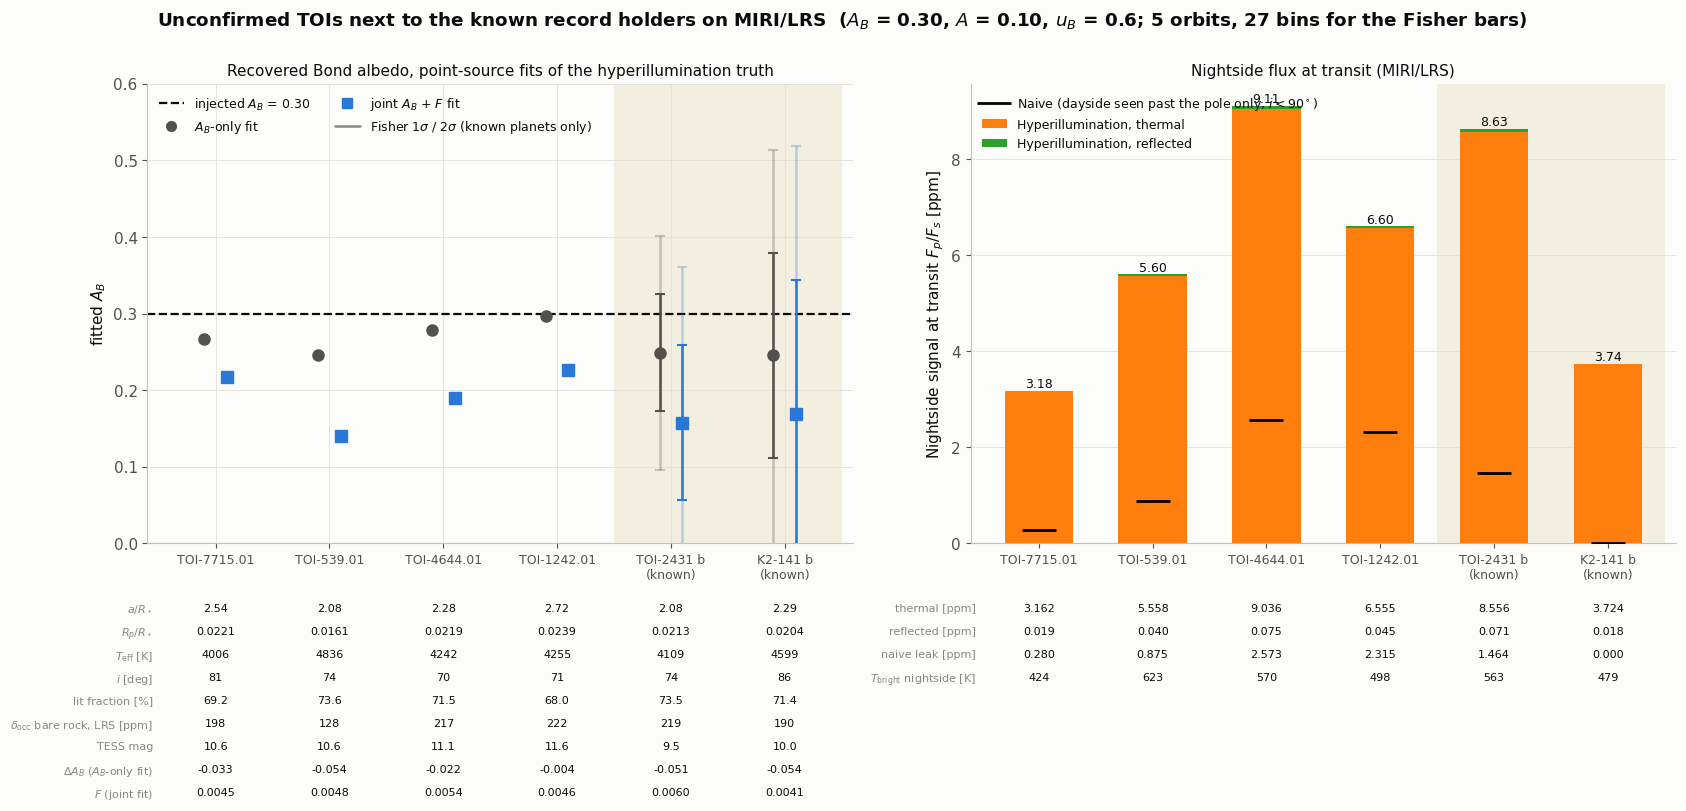

In [9]:
PAPER_MODE = False
COMPARISON_FACE = "#f3efe0"   # tint of the comparison planets (axes in 6., column spans here)


def tag(name):
    return f"{name} (known planet, comparison)" if is_comparison[name] else f"{name} (TESS candidate)"


def plot_lrs_comparison(lrs, title=None):
    names = list(lrs)
    x = np.arange(len(names))
    fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(17, 8.5))

    # left: fitted A_B, A_B-only (circle) and joint (square), Fisher bars only where there is a noise level
    for k, nm in enumerate(names):
        for j, (model, marker, color) in enumerate((("naive", "o", C_NAIVE), ("naive_redist", "s", C_REDIST))):
            r, xx = lrs[nm]["fit"][model], k + (j - 0.5) * 0.2
            if "sigma_A_B" in r:
                for lev, alpha in ((2, .3), (1, 1.)):   # widest bar first (lightest), 1 sigma on top
                    ax0.errorbar(xx, r["A_B_fit"], yerr=lev * r["sigma_A_B"], fmt="none", ecolor=color, alpha=alpha, elinewidth=1.8, capsize=3.5, capthick=1.5, zorder=3)
            ax0.plot(xx, r["A_B_fit"], marker, ms=8, color=color, zorder=4)
    ax0.axhline(A_B_true, color=INK, ls="--", lw=1.6, zorder=2)
    ax0.set_ylabel(r"fitted $A_B$"); ax0.set_ylim(0., 0.6)
    ax0.set_title("Recovered Bond albedo, point-source fits of the hyperillumination truth", fontsize=11)
    ax0.legend(handles=[plt.Line2D([], [], color=INK, ls="--", lw=1.6, label=rf"injected $A_B$ = {A_B_true:.2f}"),
                        plt.Line2D([], [], marker="o", ls="none", ms=7, color=C_NAIVE, label="$A_B$-only fit"),
                        plt.Line2D([], [], marker="s", ls="none", ms=7, color=C_REDIST, label="joint $A_B$ + $F$ fit"),
                        plt.Line2D([], [], color=MUTED, lw=1.8, label=r"Fisher 1$\sigma$ / 2$\sigma$ (known planets only)")], loc="upper left", fontsize=9, ncol=2)

    # right: nightside signal at transit, hyperillumination (stacked) and the naive leak
    thermal = np.array([lrs[nm]["night"]["thermal"] for nm in names]); reflected = np.array([lrs[nm]["night"]["reflected"] for nm in names])
    ax1.bar(x, thermal, color="C1", width=.6, label="Hyperillumination, thermal", zorder=3)
    ax1.bar(x, reflected, bottom=thermal, color="C2", width=.6, label="Hyperillumination, reflected", zorder=3)
    ax1.plot(x, [lrs[nm]["night"]["naive"] for nm in names], "k_", ms=25, mew=2, label=r"Naive (dayside seen past the pole only, $i<90^\circ$)", zorder=4)
    for xi, v in zip(x, thermal + reflected): ax1.text(xi, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
    ax1.set_ylabel(r"Nightside signal at transit $F_p/F_s$ [ppm]")
    ax1.set_title(f"Nightside flux at transit ({instrument})", fontsize=11)
    ax1.legend(loc="upper left", fontsize=9); ax1.grid(axis="x", visible=False)

    # both: planet ticks, the known planets tinted
    for ax in (ax0, ax1):
        ax.set_xticks(x, [nm + ("\n(known)" if is_comparison[nm] else "") for nm in names], fontsize=9)
        ax.set_xlim(-0.6, len(names) - 0.4)
        for k, nm in enumerate(names):
            if is_comparison[nm]: ax.axvspan(k - 0.5, k + 0.5, color=COMPARISON_FACE, zorder=0, lw=0)

    # rows under the axes: geometry, observability and fit numbers (left), nightside numbers (right)
    pls = [planets[nm] for nm in names]
    rows0 = [(r"$a/R_\star$", [pl.R / pl.r2 for pl in pls], "{:.2f}"),
             (r"$R_p/R_\star$", [pl.r1 / pl.r2 for pl in pls], "{:.4f}"),
             (r"$T_{\rm eff}$ [K]", [pl.T2_eff for pl in pls], "{:.0f}"),
             (r"$i$ [deg]", [pl.incl for pl in pls], "{:.0f}"),
             ("lit fraction [%]", [100 * pl.fraction_illuminated() for pl in pls], "{:.1f}"),
             (r"$\delta_{\rm occ}$ bare rock, LRS [ppm]", [pl.approx_occ_depth(filter_lambda(instrument), A_B=A_B_true, A_g=A) for pl in pls], "{:.0f}"),
             ("TESS mag", [tmag[nm] for nm in names], "{:.1f}"),
             (r"$\Delta A_B$ ($A_B$-only fit)", [lrs[nm]["fit"]["naive"]["bias_A_B"] for nm in names], "{:+.3f}"),
             (r"$F$ (joint fit)", [lrs[nm]["fit"]["naive_redist"]["F_fit"] for nm in names], "{:.4f}")]
    rows1 = [("thermal [ppm]", thermal, "{:.3f}"), ("reflected [ppm]", reflected, "{:.3f}"),
             ("naive leak [ppm]", [lrs[nm]["night"]["naive"] for nm in names], "{:.3f}"),
             (r"$T_{\rm bright}$ nightside [K]", [lrs[nm]["night"]["T_bright"] for nm in names], "{:.0f}")]
    below = max(_param_rows(ax0, x, rows0, y0=-0.13, dy=0.05), _param_rows(ax1, x, rows1, y0=-0.13, dy=0.05))
    fig.suptitle(title or rf"Unconfirmed TOIs next to the known record holders on {instrument}  ($A_B$ = {A_B_true:.2f}, $A$ = {A:.2f}, $u_B$ = {u_B:g}; {n_orbits} orbits, {n_bins} bins for the Fisher bars)", y=1.0, fontweight="bold")
    fig.tight_layout()
    fig.subplots_adjust(bottom=min(0.6, 0.1 + below * ax0.get_position().height))   # room for the rows (axes fraction -> figure fraction)
    return fig, (ax0, ax1)


fig, axs = plot_lrs_comparison(lrs)
paper_figure("toi_candidates_lrs_comparison", PAPER_MODE, fig=fig, tight=False)
plt.show()

## 6. Per planet

`analyse_planet` runs the four items for one planet:

1. The **`CUSTOM` line** for `HItargets_utils.py` (the `CUSTOM` dict, line 38), with the provenance in its comment; for the comparison planets it echoes what `hi_planets_by_name` already holds.
2. **`summary()`** with the approximate MIRI/LRS occultation depth.
3. **MIRI/LRS phase curve** with the fits of 5.: the hyperillumination truth with the best point-source fits ($A_B$ only, and $A_B$ + $F$ jointly), and the residuals before and after absorbing the bias. For a known planet this is `plot_fit_vs_truth`, with one mock noise realisation at its PandExo noise; for a candidate the same figure without data (`plot_truth_and_fits`). Printed below it: the recovered $A_B$ of both fits and the residual rms; for a known planet also the Fisher $\sigma$, the misfit $\sqrt{\chi^2}$ and the significance $\sqrt{\Delta\chi^2_F}$ of the spurious $F$ (`Bias_Maps.ipynb` 2.5).
4. **Retrieved $A_B$ per JWST instrument** (`instrument_retrievals` / `plot_instrument_retrievals`, after Ramirez et al. 2026 Fig. 4): the $A_B$-only fit per instrument against the injected value (dashed); Fisher $1\sigma$ / $2\sigma$ bars and the unconstrained verdict (hollow marker) only for a known planet.
5. **Nightside flux per instrument** (`nightside_flux`, as in `test_FullPhaseCurve.ipynb`): the planet signal at transit, thermal and reflected, under hyperillumination, with the naive value as a tick; table with the nightside brightness temperature.

The comparison planets are marked by tinted axes and "(known planet, comparison)" in the titles. What to look for: how a candidate's bias changes with the band (the share of reflected and thermal light and the hyperillumination signal depend on wavelength), and whether its nightside flux reaches the ppm level anywhere.

In [10]:
# comments of the CUSTOM lines: the provenance of each candidate; the comparison planets echo their existing entries
notes = {}
for p in CANDIDATES:
    d = derived(p)
    notes[p["name"]] = f"TESS {p['disposition']} (TIC {p['tic']}), ExoFOP {EXOFOP_DATE}, TIC v8 host; a/R* from rho_star = {d['a_over_r2']:.2f} +- {d['a_over_r2_err']:.2f}; r1 from the depth; incl from T14 (b = {d['b']:.2f}); UnconfirmedTOI.ipynb"
for nm in comparison:
    notes[nm] = "as returned by hi_planets_by_name (already in HItargets_utils / the archive)"


def mark_comparison(fig, name):
    '''Tint the axes of a comparison planet's figure.'''
    if is_comparison[name]:
        for a_ in fig.axes: a_.set_facecolor(COMPARISON_FACE)


def plot_truth_and_fits(cfg, A_B_true, fit, title=None, **kw):
    '''plot_fit_vs_truth without the mock data: truth and best fits (left), residuals before and after absorbing the bias (right), for a planet without a noise level.'''
    t_, truth = model_pcurve(cfg, "hyperillum", A_B_true, **kw)
    naive_0 = model_pcurve(cfg, "naive", A_B_true, **kw)[1]
    curves = []
    for model, label, ls, color in (("naive", "best $A_B$-only fit", "--", C_NAIVE), ("naive_redist", "best joint fit", "-.", C_REDIST)):
        f = fit[model]
        y = model_pcurve(cfg, model, f["A_B_fit"], F=f.get("F_fit"), **kw)[1]
        tag_ = f"$A_B$ = {f['A_B_fit']:.3f}" + (f", $F$ = {f['F_fit']:.4f}" if "F_fit" in f else "")
        curves.append((y + (truth - y).mean(), f"{label} ({tag_})", ls, color))   # the fitted baseline (free_offset)
    fig, ax = plt.subplots(1, 2, figsize=(16, 5.2))
    ax[0].plot(t_ * 24., truth, lw=1.2, color=C_HI, label="hyperillumination (truth)")
    for y, label, ls, color in curves: ax[0].plot(t_ * 24., y, lw=1.2, ls=ls, color=color, label=label)
    ax[0].set_xlabel("time [h]"); ax[0].set_ylabel(r"$F_p/F_s$ [ppm]"); ax[0].set_title("truth and best fits (no noise level for a candidate)")
    ax[1].axhline(0., color=AXIS, lw=.8)
    ax[1].plot(t_ * 24., truth - naive_0, lw=1.2, color=C_HI, label=rf"truth $-$ naive at the true $A_B$ = {A_B_true:.2f}")
    for y, label, ls, color in curves: ax[1].plot(t_ * 24., truth - y, lw=1.2, color=color, label=f"truth $-$ {label.split(' (')[0]} (irreducible)")
    ax[1].set_xlabel("time [h]"); ax[1].set_ylabel("residual [ppm]"); ax[1].set_title("residual before and after absorbing the bias")
    for a_ in ax: a_.legend(fontsize=9)
    fig.suptitle(title or rf"{cfg.planet.name}: $a/R_\star$ = {cfg.planet.R / cfg.planet.r2:.2f}", y=1.02)
    fig.tight_layout()
    return fig, ax


def nightside_table(planet):
    '''Planet signal at transit per band (nightside_flux; hyperillumination vs naive, thermal / reflected split, brightness temperature of the thermal part), as in test_FullPhaseCurve.ipynb.'''
    runs = [(ins, m, "flux") for ins in night_instruments for m in ("hyperillum", "naive")] + [(ins, "hyperillum", "temperature") for ins in night_instruments]
    out = Parallel(n_jobs=-1, backend="loky")(delayed(nightside_flux)(planet, filter_lambda(ins), m, unit=unit, filter_path=filter_loc(ins), u_B=u_B, A_B=A_B_true, A=A) for ins, m, unit in runs)
    res = dict(zip(runs, out))
    return pd.DataFrame([{"instrument": ins, "band [µm]": "{:.1f}-{:.1f}".format(*(1e6 * filter_lambda(ins))),
                          "HI thermal [ppm]": res[ins, "hyperillum", "flux"][0], "HI reflected [ppm]": res[ins, "hyperillum", "flux"][1],
                          "HI total [ppm]": sum(res[ins, "hyperillum", "flux"]), "naive total [ppm]": sum(res[ins, "naive", "flux"]),
                          "HI nightside T_bright [K]": res[ins, "hyperillum", "temperature"]} for ins in night_instruments]).set_index("instrument")


def plot_nightside_bars(night_tab, name):
    fig, ax = plt.subplots(figsize=(10, 5))
    x = np.arange(len(night_tab))
    ax.bar(x, night_tab["HI thermal [ppm]"], color="C1", label="Hyperillumination, thermal")
    ax.bar(x, night_tab["HI reflected [ppm]"], bottom=night_tab["HI thermal [ppm]"], color="C2", label="Hyperillumination, reflected")
    ax.plot(x, night_tab["naive total [ppm]"], "k_", ms=25, mew=2, label=r"Naive (dayside seen past the pole only, $i<90^\circ$)")
    for xi, v in zip(x, night_tab["HI total [ppm]"]): ax.text(xi, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(x, [f"{ins}\n{b} µm" for ins, b in zip(night_tab.index, night_tab["band [µm]"])], rotation=30, ha="right", fontsize=9)
    ax.set_ylabel(r"Nightside signal at transit $F_p/F_s$ [ppm]")
    ax.set_title(f"{tag(name)}: nightside flux at transit ($A_B$ = {A_B_true:.2f}, $A$ = {A:.2f})")
    ax.legend(loc="upper left"); ax.grid(axis="y", alpha=.3)
    fig.tight_layout()
    return fig, ax


def analyse_planet(name):
    '''The items of 6. for one planet, reusing the MIRI/LRS fits of 5.; returns its tables for the overview of 7.'''
    pl, levels, fit, known = planets[name], sigma_levels[name], lrs[name]["fit"], is_comparison[name]
    print(custom_entry_line(pl, notes[name]), "\n")
    pl.summary(eff_wavelength_range=filter_lambda(instrument))

    # 3. MIRI/LRS: truth, best point-source fits, residuals
    cfg_p = replace(cfg, planet=pl, sigma_1min=levels[instrument])
    head = rf"{tag(name)}: $a/R_\star$ = {pl.R / pl.r2:.2f}, $T_{{\rm eff}}$ = {pl.T2_eff:.0f} K, $P$ = {24 * pl.period:.2f} h, $i$ = {pl.incl:.0f}°  ({instrument}"
    if known: fig, ax = plot_fit_vs_truth(cfg_p, A_B_true, fit, **kw, title=head + rf", {cfg_p.n_orbits} orbits, $\sigma_{{\rm bin}}$ = {cfg_p.sigma_bin:.0f} ppm)")
    else:     fig, ax = plot_truth_and_fits(cfg_p, A_B_true, fit, **kw, title=head + ")")
    mark_comparison(fig, name); paper_figure(f"toi_fit_vs_truth_{name.replace(' ', '')}", PAPER_MODE, fig=fig); plt.show()   # PAPER_MODE of the calling cell
    n_, j_ = fit["naive"], fit["naive_redist"]
    print(f"A_B-only: A_B {A_B_true:.3f} -> {n_['A_B_fit']:.3f} ({100 * n_['bias_A_B'] / A_B_true:+.1f} %), residual rms {n_['rms']:.2f} ppm"
          + (f", Fisher sigma {n_['sigma_A_B']:.3f}, |bias|/sigma = {abs(n_['bias_A_B']) / n_['sigma_A_B']:.2f}, misfit sqrt(chi2) = {np.sqrt(n_['chi2']):.2f} sigma" if known else ""))
    print(f"joint:    A_B {A_B_true:.3f} -> {j_['A_B_fit']:.3f} ({100 * j_['bias_A_B'] / A_B_true:+.1f} %), F = {j_['F_fit']:.4f}, residual rms {j_['rms']:.2f} ppm"
          + (f", Fisher sigma {j_['sigma_A_B']:.3f}, spurious F at sqrt(dchi2_F) = {np.sqrt(max(n_['chi2'] - j_['chi2'], 0.)):.2f} sigma" if known else ""))

    # 4. retrieved A_B per instrument (A_B-only fit); error bars, verdicts and sigmas only for a known planet
    tab = instrument_retrievals(cfg_p, pl, retrieval_instruments, A_B_true, sigma_1min=levels, bounds=bounds, **kw)
    fig, ax = plot_instrument_retrievals(tab, sigma_levels=(1, 2) if known else (), title=f"{tag(name)}: $A_B$-only fit" + (f"  ({cfg_p.n_orbits} orbits per instrument)" if known else "  (no noise level: fitted values only)"))
    mark_comparison(fig, name); paper_figure(f"toi_retrieval_instruments_{name.replace(' ', '')}", PAPER_MODE, fig=fig); plt.show()
    cols = ["instrument", "sigma_1min", "A_B_fit", "bias_A_B", "sigma_A_B", "bias_sigma", "verdict"] if known else ["instrument", "A_B_fit", "bias_A_B"]
    print(tab[cols].to_string(index=False, na_rep="-", float_format=lambda v: f"{v:.4g}"))

    # 5. nightside flux per instrument
    night = nightside_table(pl)
    fig, ax = plot_nightside_bars(night, name)
    mark_comparison(fig, name); paper_figure(f"toi_nightside_flux_{name.replace(' ', '')}", PAPER_MODE, fig=fig); plt.show()
    print(night.round(3).to_string())

    get_reusable_executor().shutdown(wait=True)   # recycle the loky workers between planets (SPIDERMAN's allocator growth accumulates in reused workers)
    return dict(instruments=tab, nightside=night)


results = {}

### 6.1 TOI-7715.01

"TOI-7715.01": PlanetParams(name="TOI-7715.01", period=0.3236320, incl=80.8, ecc=0.0, w=90.0, r1=0.02209, r2=1.0, R=2.542, T2_eff=4006.0, a_AU=0.00791, T14=0.947),   # TESS PC (TIC 200001699), ExoFOP 2026-10-20, TIC v8 host; a/R* from rho_star = 2.54 +- 0.24; r1 from the depth; incl from T14 (b = 0.41); UnconfirmedTOI.ipynb 

=== TOI-7715.01 ===
rp = r1/r2           = 0.0221
a  = R/r2            = 2.542
terminator_penumbra  = 66.3 deg
terminator_nightside = 112.6 deg
fraction_illuminated = 69.2 %  (fully illuminated: 29.9 %, penumbra: 39.3 %)
substellar_boost     = 1.76076 % (insolation), 0.43731 % (temperature)
approx_occ_depth     = 218.8 ppm


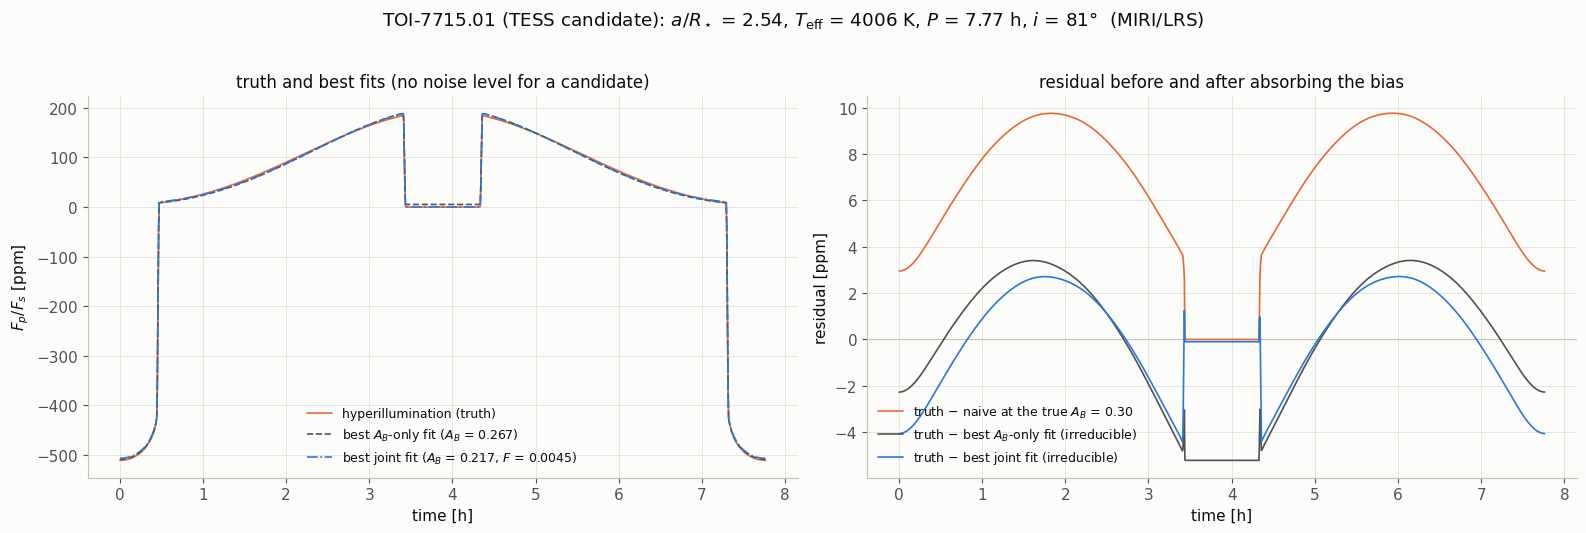

A_B-only: A_B 0.300 -> 0.267 (-11.0 %), residual rms 2.86 ppm
joint:    A_B 0.300 -> 0.217 (-27.7 %), F = 0.0045, residual rms 2.07 ppm


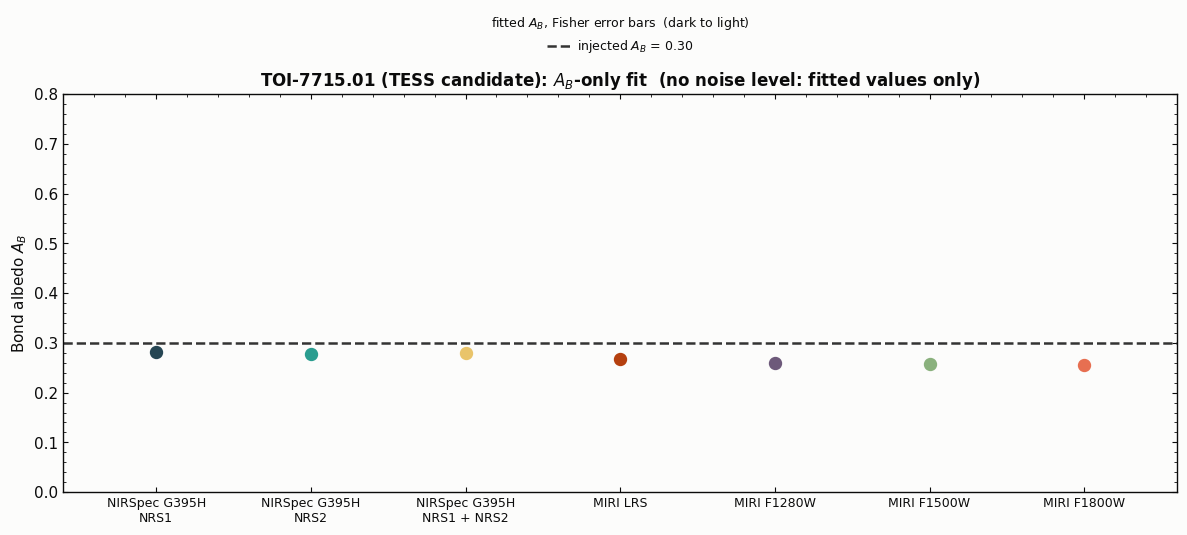

                                     instrument  A_B_fit  bias_A_B
                        JWST_NIRSpec.G395H_NRS1   0.2824  -0.01764
                        JWST_NIRSpec.G395H_NRS2   0.2767  -0.02332
JWST_NIRSpec.G395H_NRS1+JWST_NIRSpec.G395H_NRS2   0.2795  -0.02049
                                       MIRI/LRS    0.267  -0.03298
                                    MIRI/F1280W   0.2587  -0.04133
                                    MIRI/F1500W   0.2574  -0.04261
                                    MIRI/F1800W   0.2563  -0.04367


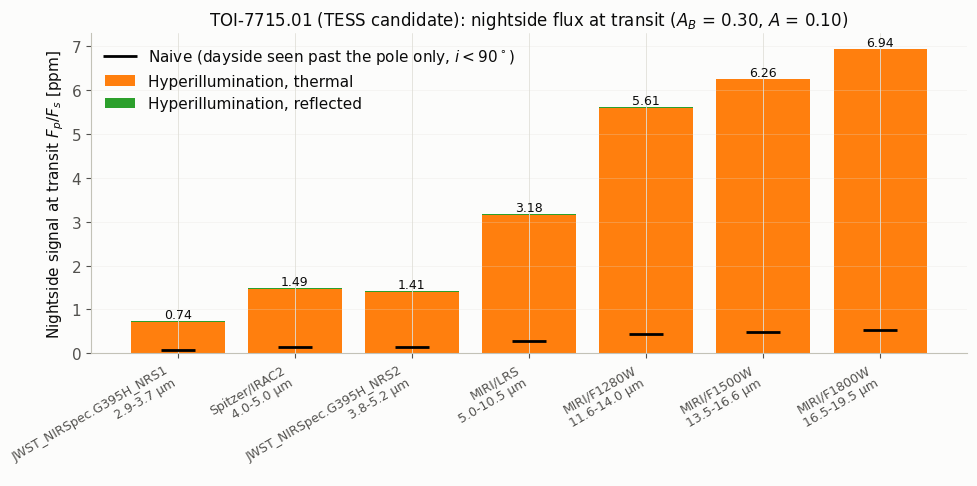

                         band [µm]  HI thermal [ppm]  HI reflected [ppm]  HI total [ppm]  naive total [ppm]  HI nightside T_bright [K]
instrument                                                                                                                            
JWST_NIRSpec.G395H_NRS1    2.9-3.7             0.717               0.019           0.736              0.073                    602.625
Spitzer/IRAC2              4.0-5.0             1.468               0.019           1.487              0.143                    533.700
JWST_NIRSpec.G395H_NRS2    3.8-5.2             1.391               0.019           1.410              0.136                    537.288
MIRI/LRS                  5.0-10.5             3.162               0.019           3.181              0.280                    424.431
MIRI/F1280W              11.6-14.0             5.587               0.019           5.606              0.447                    334.798
MIRI/F1500W              13.5-16.6             6.241   

In [11]:
PAPER_MODE = False
results["TOI-7715.01"] = analyse_planet("TOI-7715.01")

### 6.2 TOI-539.01

"TOI-539.01": PlanetParams(name="TOI-539.01", period=0.3096060, incl=74.3, ecc=0.0, w=90.0, r1=0.01605, r2=1.0, R=2.082, T2_eff=4836.0, a_AU=0.00787, T14=1.030),   # TESS PC (TIC 238004786), ExoFOP 2026-10-20, TIC v8 host; a/R* from rho_star = 2.08 +- 0.55; r1 from the depth; incl from T14 (b = 0.56); UnconfirmedTOI.ipynb 

=== TOI-539.01 ===
rp = r1/r2           = 0.0161
a  = R/r2            = 2.082
terminator_penumbra  = 60.8 deg
terminator_nightside = 118.2 deg
fraction_illuminated = 73.6 %  (fully illuminated: 25.6 %, penumbra: 48.0 %)
substellar_boost     = 1.56020 % (insolation), 0.38779 % (temperature)
approx_occ_depth     = 139.1 ppm


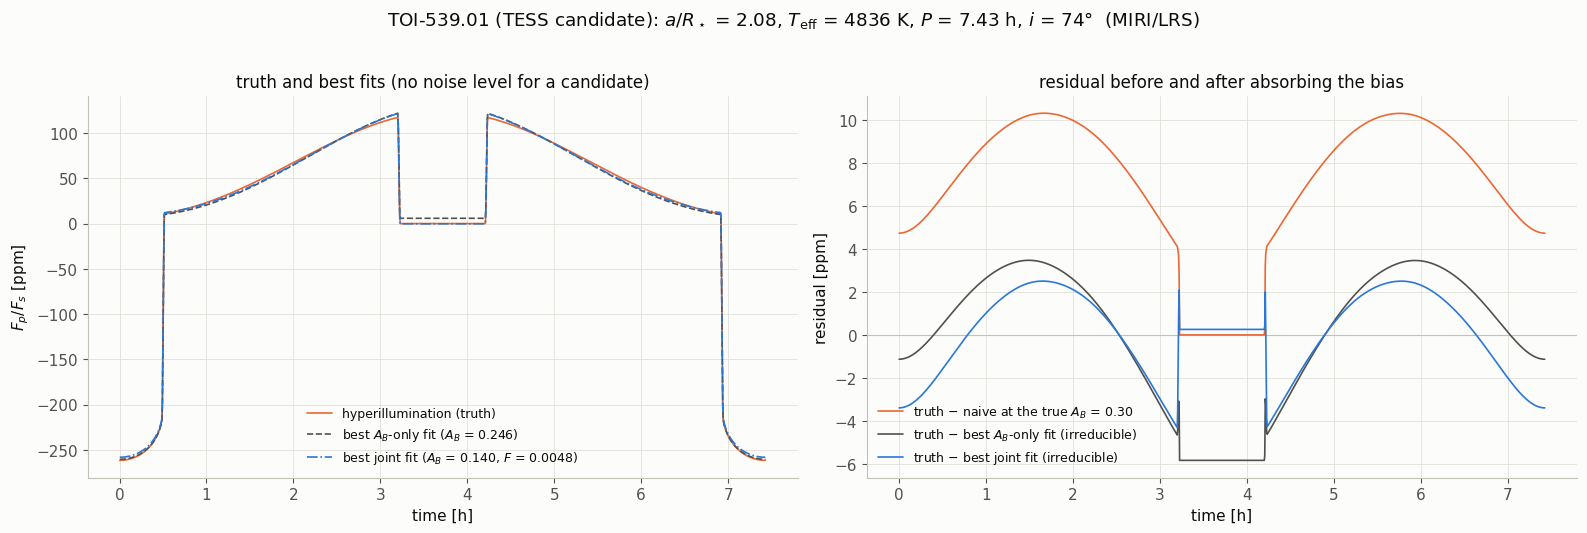

A_B-only: A_B 0.300 -> 0.246 (-18.0 %), residual rms 3.05 ppm
joint:    A_B 0.300 -> 0.140 (-53.4 %), F = 0.0048, residual rms 1.84 ppm


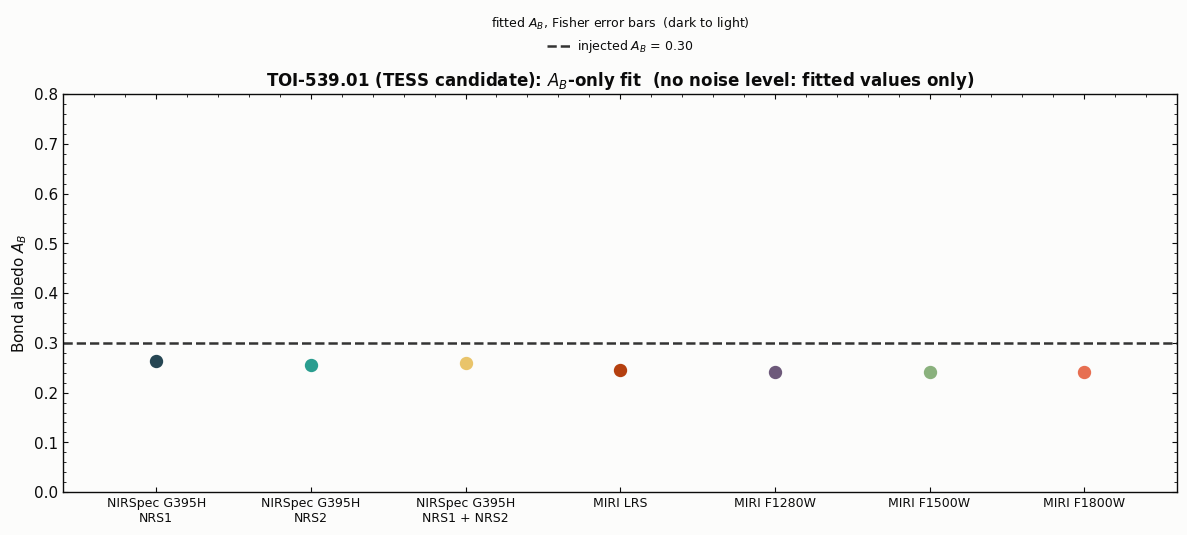

                                     instrument  A_B_fit  bias_A_B
                        JWST_NIRSpec.G395H_NRS1   0.2632  -0.03679
                        JWST_NIRSpec.G395H_NRS2   0.2555  -0.04452
JWST_NIRSpec.G395H_NRS1+JWST_NIRSpec.G395H_NRS2   0.2595  -0.04053
                                       MIRI/LRS   0.2461  -0.05388
                                    MIRI/F1280W   0.2412  -0.05878
                                    MIRI/F1500W   0.2411   -0.0589
                                    MIRI/F1800W   0.2413  -0.05871


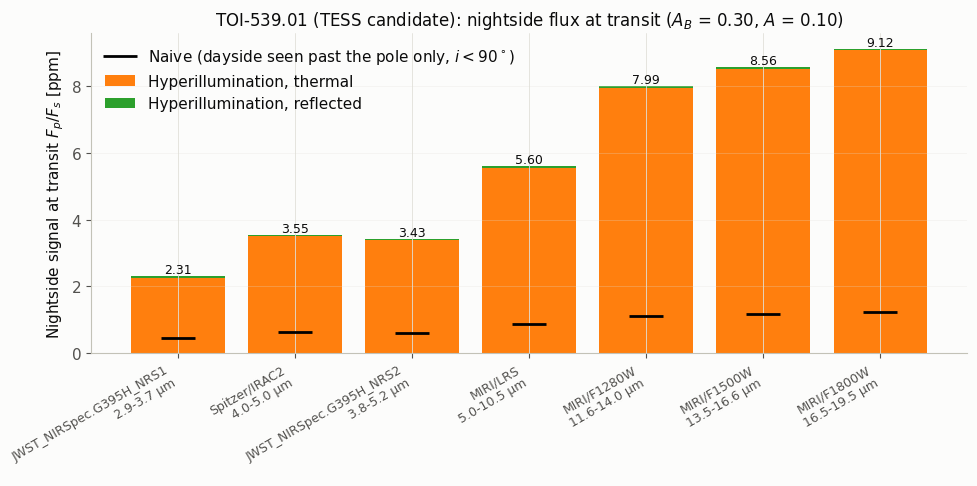

                         band [µm]  HI thermal [ppm]  HI reflected [ppm]  HI total [ppm]  naive total [ppm]  HI nightside T_bright [K]
instrument                                                                                                                            
JWST_NIRSpec.G395H_NRS1    2.9-3.7             2.267                0.04           2.307              0.445                    850.986
Spitzer/IRAC2              4.0-5.0             3.510                0.04           3.551              0.626                    756.888
JWST_NIRSpec.G395H_NRS2    3.8-5.2             3.390                0.04           3.430              0.609                    763.157
MIRI/LRS                  5.0-10.5             5.558                0.04           5.599              0.875                    623.071
MIRI/F1280W              11.6-14.0             7.953                0.04           7.993              1.125                    502.644
MIRI/F1500W              13.5-16.6             8.515   

In [12]:
PAPER_MODE = False
results["TOI-539.01"] = analyse_planet("TOI-539.01")

### 6.3 TOI-4644.01

"TOI-4644.01": PlanetParams(name="TOI-4644.01", period=0.3181850, incl=69.9, ecc=0.0, w=90.0, r1=0.02191, r2=1.0, R=2.275, T2_eff=4242.2, a_AU=0.00794, T14=0.762),   # TESS PC (TIC 387423096), ExoFOP 2026-10-20, TIC v8 host; a/R* from rho_star = 2.28 +- 0.22; r1 from the depth; incl from T14 (b = 0.78); UnconfirmedTOI.ipynb 

=== TOI-4644.01 ===
rp = r1/r2           = 0.0219
a  = R/r2            = 2.275
terminator_penumbra  = 63.3 deg
terminator_nightside = 115.5 deg
fraction_illuminated = 71.5 %  (fully illuminated: 27.5 %, penumbra: 44.0 %)
substellar_boost     = 1.95409 % (insolation), 0.48498 % (temperature)
approx_occ_depth     = 237.3 ppm


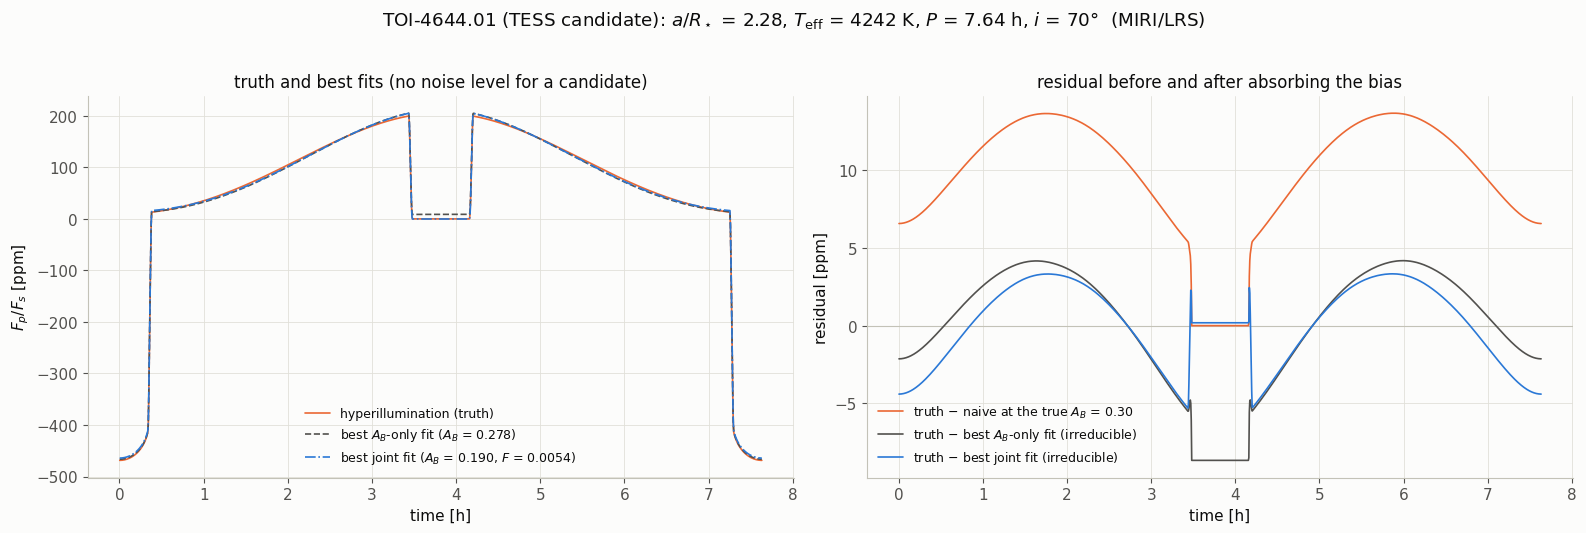

A_B-only: A_B 0.300 -> 0.278 (-7.4 %), residual rms 3.75 ppm
joint:    A_B 0.300 -> 0.190 (-36.6 %), F = 0.0054, residual rms 2.49 ppm


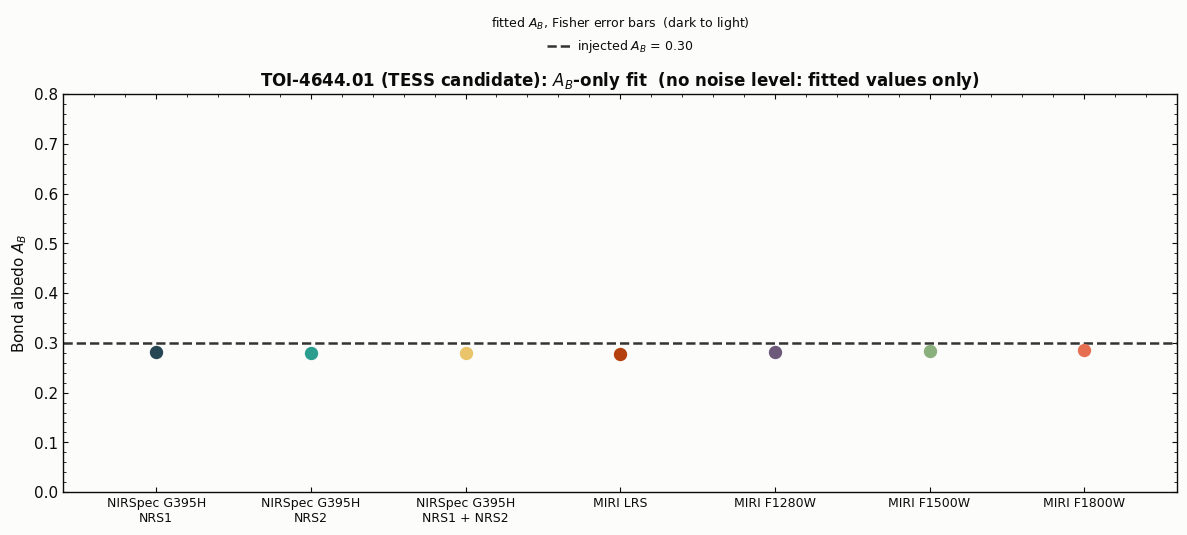

                                     instrument  A_B_fit  bias_A_B
                        JWST_NIRSpec.G395H_NRS1   0.2819  -0.01809
                        JWST_NIRSpec.G395H_NRS2   0.2792  -0.02085
JWST_NIRSpec.G395H_NRS1+JWST_NIRSpec.G395H_NRS2   0.2806  -0.01945
                                       MIRI/LRS   0.2779  -0.02209
                                    MIRI/F1280W   0.2814  -0.01858
                                    MIRI/F1500W   0.2832  -0.01676
                                    MIRI/F1800W   0.2854  -0.01458


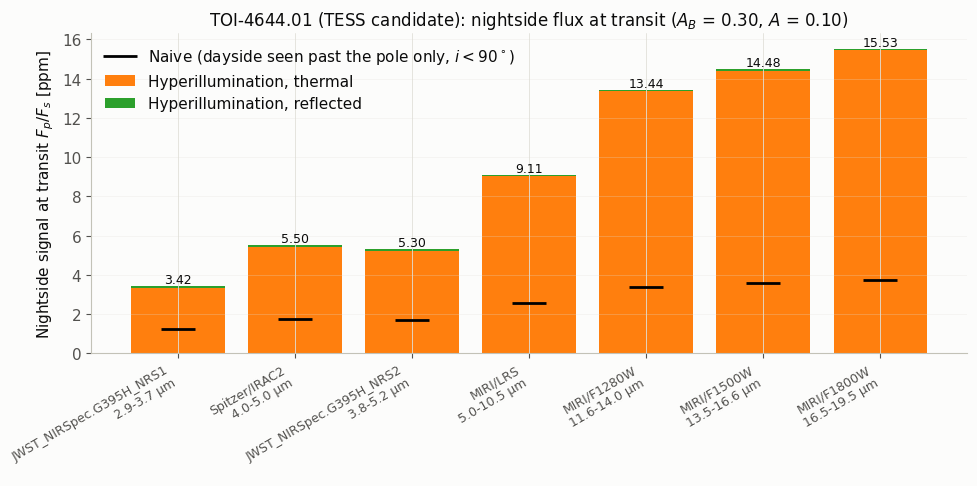

                         band [µm]  HI thermal [ppm]  HI reflected [ppm]  HI total [ppm]  naive total [ppm]  HI nightside T_bright [K]
instrument                                                                                                                            
JWST_NIRSpec.G395H_NRS1    2.9-3.7             3.343               0.075           3.417              1.214                    783.602
Spitzer/IRAC2              4.0-5.0             5.427               0.075           5.502              1.772                    696.730
JWST_NIRSpec.G395H_NRS2    3.8-5.2             5.224               0.075           5.298              1.719                    702.278
MIRI/LRS                  5.0-10.5             9.036               0.075           9.110              2.573                    569.535
MIRI/F1280W              11.6-14.0            13.362               0.075          13.437              3.389                    456.544
MIRI/F1500W              13.5-16.6            14.400   

In [13]:
PAPER_MODE = False
results["TOI-4644.01"] = analyse_planet("TOI-4644.01")

### 6.4 TOI-1242.01

"TOI-1242.01": PlanetParams(name="TOI-1242.01", period=0.3814850, incl=70.7, ecc=0.0, w=90.0, r1=0.02387, r2=1.0, R=2.717, T2_eff=4255.0, a_AU=0.00897, T14=0.565),   # TESS PC (TIC 198212955), ExoFOP 2026-10-20, TIC v8 host; a/R* from rho_star = 2.72 +- 0.24; r1 from the depth; incl from T14 (b = 0.90); UnconfirmedTOI.ipynb 

=== TOI-1242.01 ===
rp = r1/r2           = 0.0239
a  = R/r2            = 2.717
terminator_penumbra  = 67.9 deg
terminator_nightside = 111.1 deg
fraction_illuminated = 68.0 %  (fully illuminated: 31.2 %, penumbra: 36.8 %)
substellar_boost     = 1.78075 % (insolation), 0.44225 % (temperature)
approx_occ_depth     = 246.5 ppm


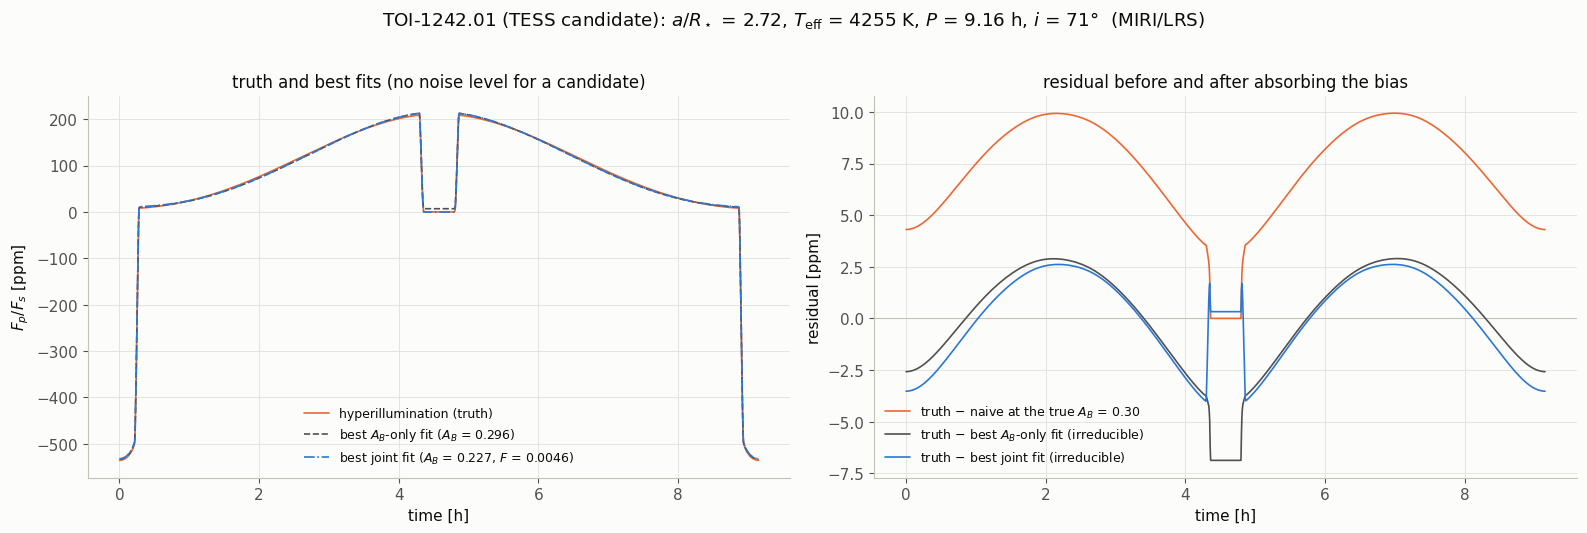

A_B-only: A_B 0.300 -> 0.296 (-1.3 %), residual rms 2.52 ppm
joint:    A_B 0.300 -> 0.227 (-24.4 %), F = 0.0046, residual rms 2.00 ppm


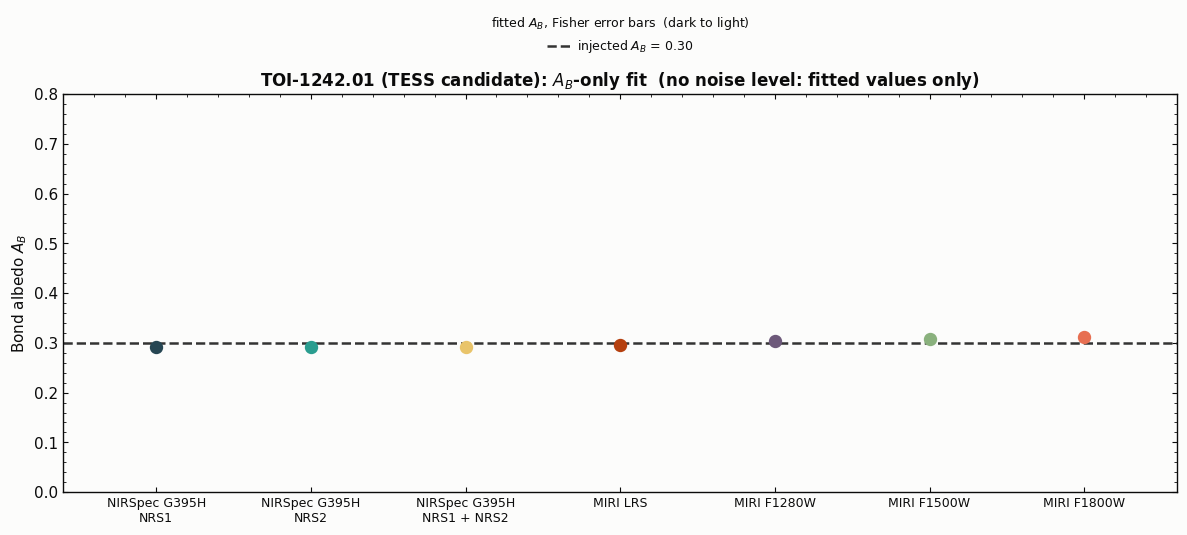

                                     instrument  A_B_fit  bias_A_B
                        JWST_NIRSpec.G395H_NRS1   0.2922 -0.007819
                        JWST_NIRSpec.G395H_NRS2   0.2925 -0.007536
JWST_NIRSpec.G395H_NRS1+JWST_NIRSpec.G395H_NRS2   0.2923 -0.007677
                                       MIRI/LRS   0.2962  -0.00376
                                    MIRI/F1280W   0.3048  0.004751
                                    MIRI/F1500W   0.3077  0.007667
                                    MIRI/F1800W   0.3109   0.01093


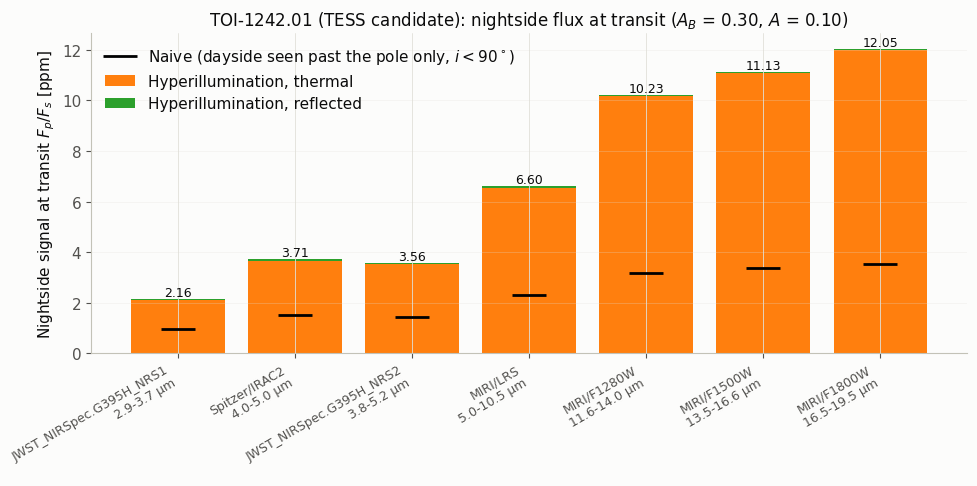

                         band [µm]  HI thermal [ppm]  HI reflected [ppm]  HI total [ppm]  naive total [ppm]  HI nightside T_bright [K]
instrument                                                                                                                            
JWST_NIRSpec.G395H_NRS1    2.9-3.7             2.112               0.045           2.157              0.968                    703.608
Spitzer/IRAC2              4.0-5.0             3.666               0.045           3.711              1.502                    621.471
JWST_NIRSpec.G395H_NRS2    3.8-5.2             3.512               0.045           3.557              1.451                    626.386
MIRI/LRS                  5.0-10.5             6.555               0.045           6.600              2.315                    497.829
MIRI/F1280W              11.6-14.0            10.187               0.045          10.233              3.170                    391.847
MIRI/F1500W              13.5-16.6            11.087   

In [14]:
PAPER_MODE = False
results["TOI-1242.01"] = analyse_planet("TOI-1242.01")

### 6.5 Comparison: TOI-2431 b (known planet)
Same analysis at its published geometry and its own PandExo / `CUSTOM_SIGMA_1MIN` noise levels.

"TOI-2431 b": PlanetParams(name="TOI-2431 b", period=0.2241958, incl=74.0, ecc=0.0, w=90.0, r1=0.02131, r2=1.0, R=2.081, T2_eff=4109.0, a_AU=0.00630, T14=0.748),   # as returned by hi_planets_by_name (already in HItargets_utils / the archive) 

=== TOI-2431 b ===
rp = r1/r2           = 0.0213
a  = R/r2            = 2.081
terminator_penumbra  = 60.6 deg
terminator_nightside = 118.1 deg
fraction_illuminated = 73.5 %  (fully illuminated: 25.5 %, penumbra: 48.1 %)
substellar_boost     = 2.07999 % (insolation), 0.51599 % (temperature)
approx_occ_depth     = 238.3 ppm


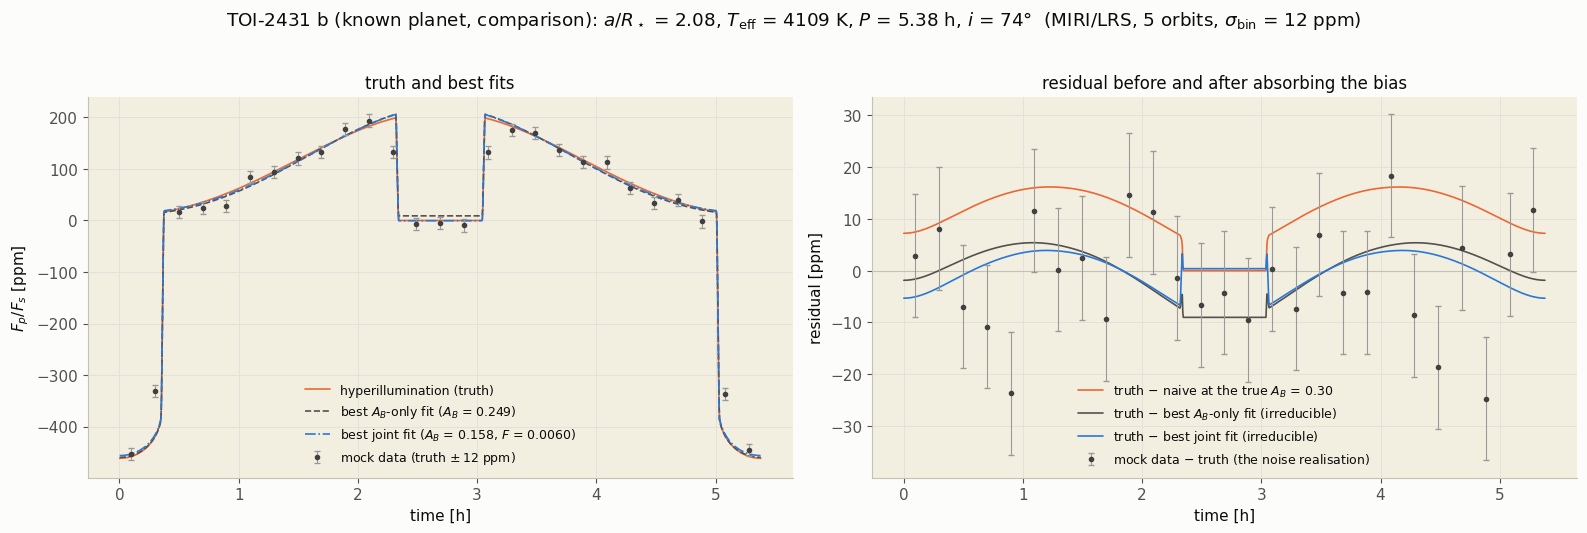

A_B-only: A_B 0.300 -> 0.249 (-17.1 %), residual rms 4.71 ppm, Fisher sigma 0.076, |bias|/sigma = 0.67, misfit sqrt(chi2) = 2.06 sigma
joint:    A_B 0.300 -> 0.158 (-47.5 %), F = 0.0060, residual rms 2.86 ppm, Fisher sigma 0.101, spurious F at sqrt(dchi2_F) = 1.64 sigma


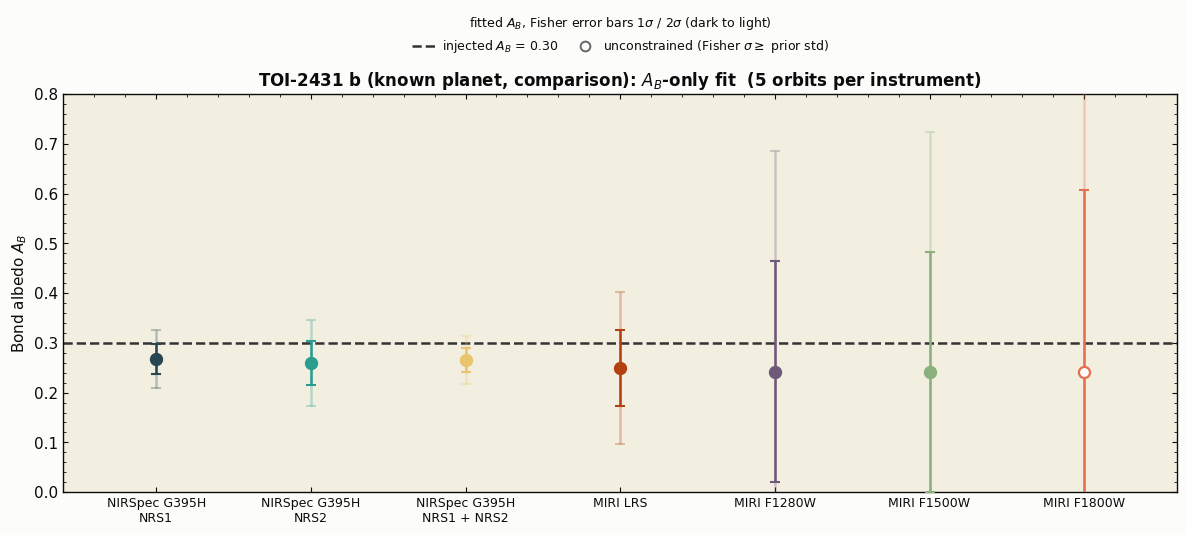

                                     instrument  sigma_1min  A_B_fit  bias_A_B  sigma_A_B  bias_sigma          verdict
                        JWST_NIRSpec.G395H_NRS1       39.24   0.2678  -0.03222    0.02947       1.093 needs hyperillum
                        JWST_NIRSpec.G395H_NRS2        56.2   0.2598  -0.04024    0.04347      0.9255         naive OK
JWST_NIRSpec.G395H_NRS1+JWST_NIRSpec.G395H_NRS2           -   0.2652  -0.03476    0.02439       1.425 needs hyperillum
                                       MIRI/LRS        91.9   0.2488  -0.05123    0.07645      0.6701         naive OK
                                    MIRI/F1280W       247.2   0.2418  -0.05824      0.222      0.2623         naive OK
                                    MIRI/F1500W         264   0.2412  -0.05876     0.2409      0.2439         naive OK
                                    MIRI/F1800W       396.2   0.2411  -0.05891     0.3672      0.1604    unconstrained


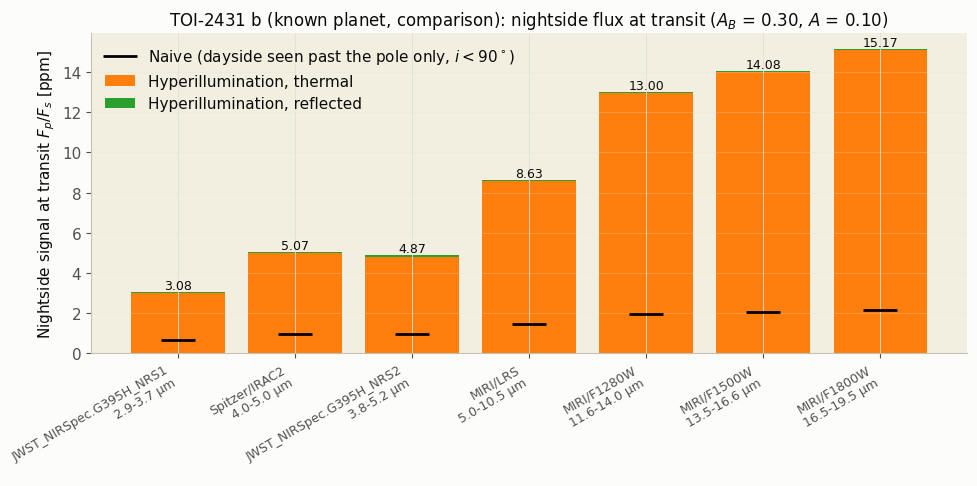

                         band [µm]  HI thermal [ppm]  HI reflected [ppm]  HI total [ppm]  naive total [ppm]  HI nightside T_bright [K]
instrument                                                                                                                            
JWST_NIRSpec.G395H_NRS1    2.9-3.7             3.004               0.071           3.075              0.655                    769.238
Spitzer/IRAC2              4.0-5.0             4.994               0.071           5.065              0.982                    685.845
JWST_NIRSpec.G395H_NRS2    3.8-5.2             4.799               0.071           4.871              0.951                    691.094
MIRI/LRS                  5.0-10.5             8.556               0.071           8.627              1.464                    563.046
MIRI/F1280W              11.6-14.0            12.933               0.071          13.004              1.962                    454.247
MIRI/F1500W              13.5-16.6            14.004   

In [15]:
PAPER_MODE = False
results["TOI-2431 b"] = analyse_planet("TOI-2431 b")

### 6.6 Comparison: K2-141 b (known planet)
Same analysis; PandExo noise on LRS and NIRSpec, no level for the MIRI imaging bands (left out of its per-instrument figure).

"K2-141 b": PlanetParams(name="K2-141 b", period=0.2803244, incl=86.3, ecc=0.0, w=90.0, r1=0.02037, r2=1.0, R=2.292, T2_eff=4599.0, a_AU=0.00747, T14=0.940),   # as returned by hi_planets_by_name (already in HItargets_utils / the archive) 

=== K2-141 b ===
rp = r1/r2           = 0.0204
a  = R/r2            = 2.292
terminator_penumbra  = 63.6 deg
terminator_nightside = 115.3 deg
fraction_illuminated = 71.4 %  (fully illuminated: 27.7 %, penumbra: 43.6 %)
substellar_boost     = 1.80147 % (insolation), 0.44736 % (temperature)
approx_occ_depth     = 207.3 ppm


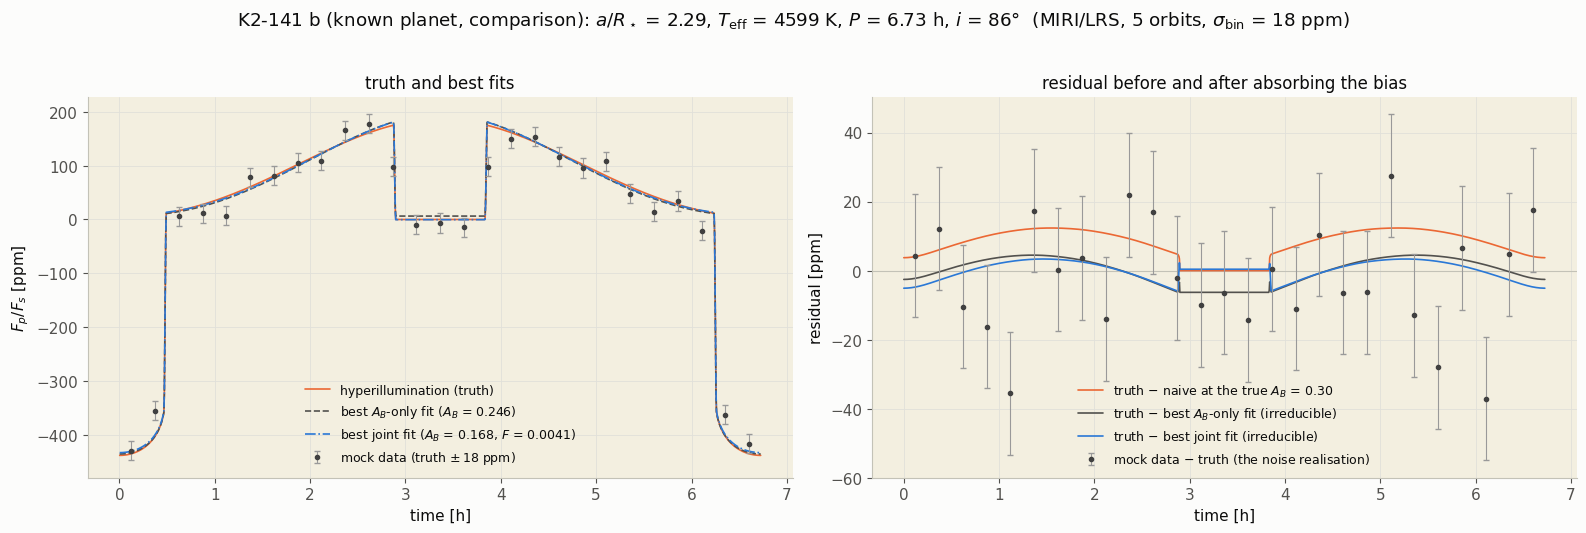

A_B-only: A_B 0.300 -> 0.246 (-18.1 %), residual rms 3.71 ppm, Fisher sigma 0.134, |bias|/sigma = 0.41, misfit sqrt(chi2) = 1.08 sigma
joint:    A_B 0.300 -> 0.168 (-43.9 %), F = 0.0041, residual rms 2.52 ppm, Fisher sigma 0.175, spurious F at sqrt(dchi2_F) = 0.79 sigma


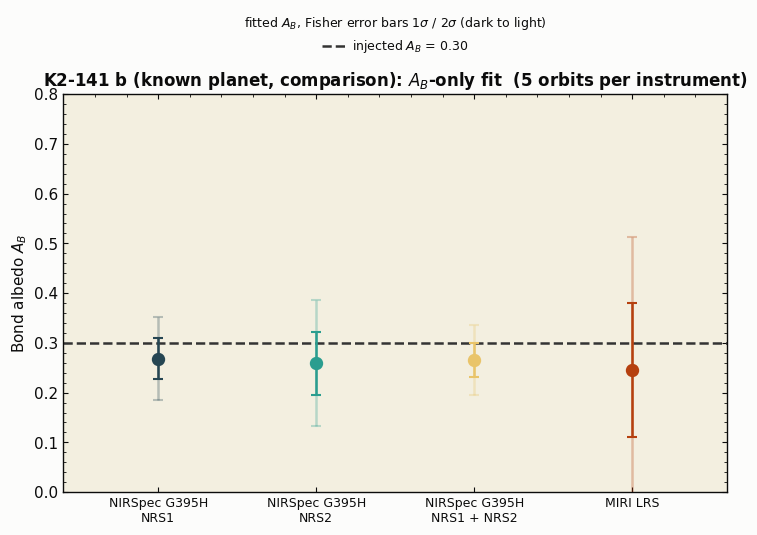

                                     instrument  sigma_1min  A_B_fit  bias_A_B  sigma_A_B  bias_sigma  verdict
                        JWST_NIRSpec.G395H_NRS1          53   0.2683  -0.03172    0.04185      0.7579 naive OK
                        JWST_NIRSpec.G395H_NRS2       77.73   0.2593  -0.04075    0.06303      0.6465 naive OK
JWST_NIRSpec.G395H_NRS1+JWST_NIRSpec.G395H_NRS2           -   0.2655  -0.03451    0.03486      0.9898 naive OK
                                       MIRI/LRS       154.5   0.2456  -0.05445      0.134      0.4063 naive OK


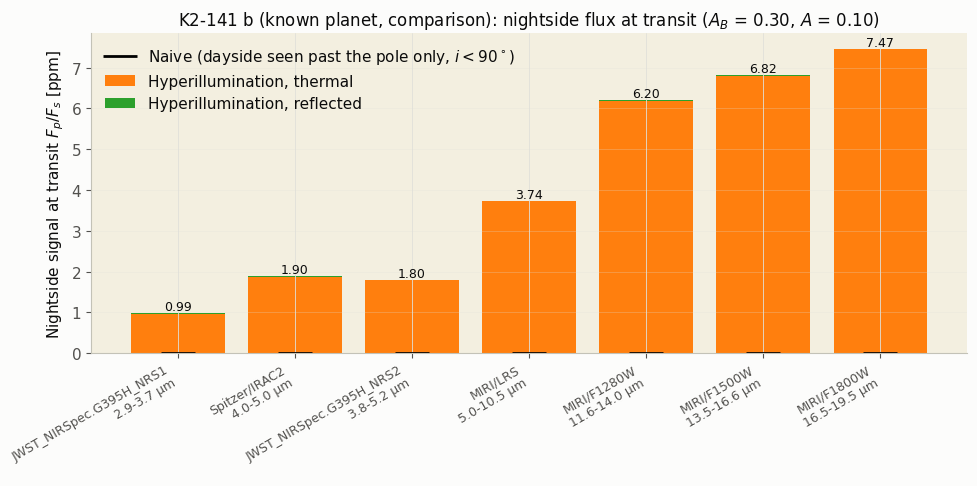

                         band [µm]  HI thermal [ppm]  HI reflected [ppm]  HI total [ppm]  naive total [ppm]  HI nightside T_bright [K]
instrument                                                                                                                            
JWST_NIRSpec.G395H_NRS1    2.9-3.7             0.970               0.018           0.988                0.0                    666.831
Spitzer/IRAC2              4.0-5.0             1.878               0.018           1.896                0.0                    593.639
JWST_NIRSpec.G395H_NRS2    3.8-5.2             1.785               0.018           1.803                0.0                    597.801
MIRI/LRS                  5.0-10.5             3.724               0.018           3.742                0.0                    478.936
MIRI/F1280W              11.6-14.0             6.177               0.018           6.195                0.0                    380.065
MIRI/F1500W              13.5-16.6             6.802   

In [16]:
PAPER_MODE = False
results["K2-141 b"] = analyse_planet("K2-141 b")

## 7. Overview
The numbers of 5. and 6. side by side (no new computation), one column per planet: geometry, the MIRI/LRS fits (recovered $A_B$ of both fits, the spurious $F$, residual rms; Fisher $\sigma$, $|\Delta A_B|/\sigma$, $\sqrt{\chi^2}$ and the verdict counts only for the known planets), the range of the per-instrument bias, and the hyperillumination nightside signal on MIRI/LRS.

In [17]:
rows = []
for nm, r in results.items():
    pl, n_, j_, tab, night, known = planets[nm], lrs[nm]["fit"]["naive"], lrs[nm]["fit"]["naive_redist"], r["instruments"], r["nightside"], is_comparison[nm]
    rows.append({"name": nm, "known planet": known, "a/R*": pl.R / pl.r2, "Rp/R*": pl.r1 / pl.r2, "T_eff [K]": pl.T2_eff, "i [deg]": pl.incl, "lit fraction [%]": 100 * pl.fraction_illuminated(),
                 "sigma_1min LRS [ppm/min]": sigma_levels[nm][instrument] if known else None,
                 "A_B fit (A_B-only)": n_["A_B_fit"], "bias": n_["bias_A_B"], "residual rms [ppm]": n_["rms"],
                 "Fisher sigma_A_B": n_.get("sigma_A_B"), "|bias| / sigma": abs(n_["bias_A_B"]) / n_["sigma_A_B"] if known else None, "misfit sqrt(chi2)": np.sqrt(n_["chi2"]) if known else None,
                 "A_B fit (joint)": j_["A_B_fit"], "F fit": j_["F_fit"], "sqrt(dchi2_F)": np.sqrt(max(n_["chi2"] - j_["chi2"], 0.)) if known else None,
                 "bias per instrument, min / max": f"{tab['bias_A_B'].min():+.3f} / {tab['bias_A_B'].max():+.3f}",
                 "instruments 'needs hyperillum' / unconstrained": f"{int((tab['verdict'] == VERDICT_NEEDS_HI).sum())} / {int((tab['verdict'] == VERDICT_UNCONSTRAINED).sum())} of {len(tab)}" if known else None,
                 "nightside HI LRS [ppm]": night.loc[instrument, "HI total [ppm]"], "nightside T_bright LRS [K]": night.loc[instrument, "HI nightside T_bright [K]"]})
show_table(pd.DataFrame(rows))

name,TOI-7715.01,TOI-539.01,TOI-4644.01,TOI-1242.01,TOI-2431 b,K2-141 b
known planet,False,False,False,False,True,True
a/R*,2.542,2.082,2.275,2.717,2.081,2.292
Rp/R*,0.02209,0.01605,0.02191,0.02387,0.02131,0.02037
T_eff [K],4006,4836,4242,4255,4109,4599
i [deg],80.79,74.29,69.92,70.73,74,86.3
lit fraction [%],69.23,73.63,71.49,67.96,73.52,71.37
sigma_1min LRS [ppm/min],-,-,-,-,91.9,154.5
A_B fit (A_B-only),0.267,0.2461,0.2779,0.2962,0.2488,0.2456
bias,-0.03298,-0.05388,-0.02209,-0.00376,-0.05123,-0.05445
residual rms [ppm],2.856,3.054,3.752,2.519,4.708,3.713
